<img src=https://audiovisuales.icesi.edu.co/assets/custom/images/ICESI_logo_prin_descriptor_RGB_POSITIVO_0924.jpg width=200>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/juanestebancg2806/sugarcane-yield-quality-prediction/blob/main/03_comparacion_modelos_ipsa.ipynb)

# **Proyecto Caña de Azúcar**
## Modelado y generación de insights para el TCH y la sacarosa en el Ingenio Providencia


--------------------------------------------------------------------

**Aprendizaje Automático II - Proyecto final**

**Profesor:** Anibal Sosa

**Integrantes:**

*   Juan David Martínez Legarda
*   Daniel Velasco López
*   Juan Esteban Cardona García
*   Katherin Adriana Camargo Cetina

Fecha: 22/11/2026

________________________________________________________________________

# IPSA (CC01-1940): comparación de modelos de clasificación

En este notebook se construyen y comparan modelos para clasificar cada cosecha de la variedad CC01-1940 en un nivel bajo, medio o alto de tonelaje (`TCH`, toneladas de caña por hectárea) y de sacarosa (porcentaje de sacarosa en la caña). Los dos targets se tratan como problemas independientes.

**Escenario de uso.** Los modelos clasifican una cosecha en el momento de programar su corte. En ese momento se conocen el número de corte, la dosis de madurante y el grupo de tenencia, y, como la fecha de corte ya está programada, también la edad del cultivo, las semanas desde la aplicación del madurante y el mes de cosecha. La lluvia registrada se acumula hasta la cosecha con una ventana que no está documentada, así que solo se conoce completa cerca del corte. Por eso los modelos describen la programación del corte y no un pronóstico con meses de anticipación. Las variables que se miden en la cosecha o en el molino quedan fuera de los predictores.

El recorrido va de lo simple a lo complejo: dos clasificadores sin predictores como piso, la regresión logística multinomial con regularización y KNN como modelos de referencia, y Random Forest, XGBoost y máquinas de vectores de soporte (SVM) como modelos avanzados. Después se prueban dos alternativas: agregar el resultado de la cosecha anterior de cada suerte, y predecir el valor continuo de cada target con un modelo de regresión para asignar la clase con los umbrales del Ingenio.

Para que la comparación sea justa, todos los modelos comparten el preprocesamiento, la partición en entrenamiento y prueba, los pliegues de validación cruzada y el criterio de selección. Así, una diferencia de desempeño se puede atribuir al modelo y no a la forma de evaluarlo.

**Criterios generales**

- La partición 80/20 se hace al inicio y se agrupa por periodo de cosecha: ningún mes de cosecha aparece a la vez en entrenamiento y en prueba.
- Los hiperparámetros y la selección de modelos se deciden con validación cruzada sobre el entrenamiento, con la misma agrupación: 5 pliegues repetidos con 3 asignaciones distintas de los periodos, para un total de 15 pliegues fijos y comunes a todos los modelos.
- La imputación, la codificación y el escalado se estiman dentro de un `Pipeline`, de modo que en cada pliegue solo usan los datos de entrenamiento de ese pliegue.
- La regla para elegir el mejor modelo se fija antes de comparar los modelos.
- El conjunto de prueba se usa una sola vez, al final, con todos los modelos ya elegidos.

**Estructura**

1. Carga del dataset procesado
2. Preprocesamiento
3. Partición, pliegues de validación cruzada y auditoría de fuga de información
4. Métricas y regla de elección del modelo
5. Modelos de referencia: clasificadores sin predictores, regresión logística multinomial y KNN
6. Modelos avanzados: Random Forest, XGBoost, SVM, historial de la suerte y regresión con umbrales
7. Comparación en validación cruzada y elección del modelo
8. Evaluación en el conjunto de prueba
9. Interpretabilidad
10. Conclusiones

## Punto de partida: qué dejó el análisis exploratorio

El EDA y la preparación de los datos se hicieron en `01_eda_ipsa.ipynb`. A continuación se resume lo que se necesita de ese trabajo para el modelado.

**Los datos.** `BD_IPSA_1940.xlsx` es un subconjunto del Ingenio Providencia con 2187 cosechas entre julio de 2014 y enero de 2021. Todas comparten tres condiciones: la variedad CC01-1940, la maduración química con BONUS 250 EC y la cosecha mecanizada en verde. Las conclusiones aplican solo a suertes con esas características. Cada fila es una suerte (identificada por la hacienda `FAZ` y la suerte `TAL`) cosechada en un mes (`periodo`, en formato AAAAMM). El dataset tiene 1115 suertes de 285 haciendas, y 629 de esas suertes aparecen en dos o más cosechas, así que los registros no son independientes entre sí.

**Las clases.** Cada target se divide en tres niveles con los umbrales del Ingenio:

| Clase | `TCH` (t/ha) | Sacarosa (%) |
|---|---|---|
| Bajo | menos de 125 | menos de 12.2 |
| Medio | de 125 a 150 | de 12.2 a 12.9 |
| Alto | más de 150 | desde 13.0 |

Los umbrales son valores fijos que no dependen de los datos, así que construir las clases no filtra información del conjunto de prueba. El umbral inferior coincide con el percentil 25 de cada target, y el superior queda cerca del percentil 60. La clase baja es la más pequeña en los dos targets, y es la que motiva acciones de manejo: una cosecha de bajo tonelaje lleva a revisar la suerte o a evaluar su renovación, y una de baja sacarosa, a ajustar la maduración o la fecha de corte. Por eso interesa medir, además del desempeño global, qué tan bien la detecta cada modelo. Los 4 registros con `TCH` menor que 60 t/ha se consideraron errores de registro: no tienen clase de `TCH`, pero conservan la de sacarosa. Los dos targets tienen una correlación débil (Spearman de −0.21), así que se modelan como dos problemas independientes.

**Los predictores y su justificación.** El modelo principal usa 7 variables originales, comunes a los dos targets:

| Predictor | Qué mide | Por qué entra | Tratamiento |
|---|---|---|---|
| `edad` | Edad del cultivo en la cosecha (meses) | Más edad, más biomasa acumulada; en sacarosa la relación tiene forma de U invertida | Sin nulos |
| `cortes` | Número de corte de la cepa | El tonelaje baja con cada corte sucesivo | Sin nulos |
| `semsmad` | Semanas entre la aplicación del madurante y el corte | La sacarosa sube hasta unas 12 semanas y luego se estabiliza | 2 valores negativos tratados como faltantes |
| `dosismad` | Dosis de madurante (L/ha) | Fundamento agronómico. En el EDA no mostró relación con los targets, pero el 98 % de las dosis está entre 0.5 y 1.5 L/ha, un rango demasiado estrecho para descartar su efecto | 2 valores inválidos (0.0 y 9.0) tratados como faltantes |
| `lluvias` | Lluvia registrada (mm), con ventana de acumulación no documentada | Principal predictor numérico de la sacarosa (Spearman de −0.28) | El 31.3 % son ceros que corresponden a falta de medición; se imputan con la mediana del mes de cosecha y se acotan en el percentil 99 |
| `mes` | Mes de cosecha | La sacarosa tiene dos máximos al año, tras cada temporada seca del valle del río Cauca [2] | Dos armónicos (periodos de 12 y 6 meses), que capturan el 93 % de la variación mensual de la sacarosa |
| `grupo_tenencia` | Grupo de tenencia de la hacienda (códigos 1, 2 y 3 sin significado documentado) | Relación débil con `TCH` | Variables indicadoras, con el código 1 como referencia |

Con los cuatro armónicos del mes y las dos indicadoras de la tenencia, las 7 variables generan 11 columnas en la matriz de diseño. En el EDA, ningún predictor numérico candidato tuvo un VIF mayor que 5. El VIF de la matriz de diseño completa, que incluye los armónicos y las indicadoras, se calcula con el conjunto de entrenamiento en la sección 3.

**Lo que quedó fuera de los predictores**

| Columnas | Motivo |
|---|---|
| `NOME`, `FAZ`, `TAL` | Identifican la cosecha, no describen el cultivo. `FAZ` y `TAL` se usan para identificar cada suerte |
| `variedad`, `madurada`, `producto`, `tipocorte` | Son constantes en todo el dataset |
| `vejez` (horas entre el corte y el molino) y `me` (materia extraña, con confianza moderada) | Se miden al recibir la caña en el molino, después del corte. Usarlas sería fuga de información |
| `pct_diatrea` (porcentaje de entrenudos barrenados por *Diatraea*) | Según la metodología de Cenicaña, se mide en la cosecha, muestreando 100 tallos por suerte y contando los entrenudos barrenados [1]. Los datos no muestran que el Ingenio la estime antes del corte, así que no está disponible en el escenario de uso. Su aporte se evalúa como prueba de robustez en la sección 7 |
| `TCH` y sacarosa como predictores del otro target | Los dos se conocen solo después de la cosecha |
| `periodo` | Se usa para agrupar la partición y la validación cruzada, no como predictor. Su parte estacional entra por `mes` |
| `anio` | En el EDA, su relación con `TCH` la dominaba un solo año (2017, el de mayor lluvia), y un modelo aplicado a cosechas futuras no puede extrapolar el efecto de años que no vio. En el análisis de regresión del histórico de suertes, además, el efecto del año reflejaba condiciones propias de cada periodo, comunes a todas las fincas, que no se trasladan a una zafra nueva. Su aporte se evalúa como prueba de robustez en la sección 7 |
| `lluvia_sin_dato` | En el EDA, los registros sin lluvia medida no difieren de los demás en ninguno de los dos targets: su información mutua con ambos quedó por debajo del nivel de ruido |

**Relaciones que encontró el EDA**

- Todas las relaciones con los targets son débiles: ningún predictor numérico supera una correlación de Spearman de 0.29 en valor absoluto. Se espera un poder predictivo limitado.
- El tonelaje se relaciona sobre todo con el número de corte (Spearman de −0.27) y con la edad del cultivo (0.15), y no tiene estacionalidad: sus medianas mensuales van de 141 a 152 t/ha.
- La sacarosa depende sobre todo de la época de cosecha: el mes explica el 21 % de su variación, con medianas más altas en marzo, septiembre y octubre (13.2 % a 13.4 %) y más bajas entre abril y julio (12.1 % a 12.5 %). Más lluvia se asocia con menos sacarosa.
- Dos relaciones con la sacarosa no son lineales: con la edad tiene forma de U invertida (sube de 12.5 % a cerca de 13.0 % hacia los 12.5 meses y baja después), y con las semanas de madurante crece hasta unas 12 semanas y luego se estabiliza. Un modelo lineal en esas variables no las captura por completo.

**Limitaciones de los datos**

- `lluvias` es un único valor por registro, con una ventana de acumulación no documentada, y casi un tercio de sus valores no tiene medición.
- El significado de `me` y de los códigos de `grupo_tenencia` no está confirmado por el Ingenio, y el de `semsmad` se dedujo de los datos.
- Parte de la variación de la sacarosa depende de factores posteriores al corte (materia extraña y horas hasta el molino), que no están disponibles antes de la cosecha.

In [1]:
# Librerías generales del notebook. Los módulos de scikit-learn y xgboost se importan en la sección donde se usan.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", None)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

%matplotlib inline

# Versiones usadas, para la reproducibilidad de los resultados
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | "
      f"xgboost {xgboost.__version__}")

pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1 | xgboost 3.4.1


## 1. Carga del dataset procesado

La última celda de `01_eda_ipsa.ipynb` guarda el dataset en `datos/ipsa_limpio.parquet`. El archivo trae solo transformaciones que dan el mismo resultado en cada fila sin importar las demás: los valores inválidos de `lluvias`, `dosismad` y `semsmad` convertidos en faltantes, la marca `excluir_tch` y las clases con los umbrales del Ingenio. No trae ninguna imputación, porque los estadísticos para imputar deben calcularse solo con el conjunto de entrenamiento.

Antes de modelar se verifica que el archivo conserve lo establecido en el EDA:

- 2187 cosechas y 22 columnas, sin repetir la combinación de hacienda, suerte y periodo.
- Los faltantes de los predictores: 685 en `lluvias`, 2 en `semsmad` y 2 en `dosismad`. Si alguno cambia, el archivo llegó imputado.
- 4 registros con `excluir_tch`, sin clase de `TCH`, y clase de sacarosa en todos los registros.
- Que cada clase se pueda reconstruir con los umbrales del Ingenio a partir de su propio target. Así se confirma que las clases no dependen de ningún estadístico del dataset.

Además, las clases se codifican como enteros ordenados (bajo = 0, medio = 1, alto = 2), porque XGBoost no acepta etiquetas de texto. Es un mapeo fijo, sin estadísticos. Los armónicos del mes que trae el archivo no se usan: se recalculan dentro del pipeline a partir de `mes` (sección 2). `pct_diatrea` y `anio` se conservan en el DataFrame solo para las pruebas de robustez de la sección 7. Si alguna verificación falla, el notebook se detiene.

In [2]:
# 1. Carga del dataset procesado (salida de 01_eda_ipsa.ipynb) y verificación de sus propiedades
RANDOM_STATE = 42  # semilla común a la partición, los pliegues y los modelos
RUTA_IPSA = Path("datos/ipsa_limpio.parquet")

# Propiedades del archivo establecidas en 01_eda_ipsa.ipynb
FILAS_ESPERADAS, COLUMNAS_ESPERADAS = 2187, 22
NULOS_ESPERADOS = {"lluvias": 685, "semsmad": 2, "dosismad": 2}
FILAS_EXCLUIR_TCH = 4

# Predictores del modelo principal en su forma original. mes entra como número: sus armónicos se calculan en el pipeline
PREDICTORES_NUMERICOS = ["edad", "cortes", "semsmad", "lluvias", "dosismad"]
PREDICTOR_MES = "mes"
PREDICTORES_CATEGORICOS = ["grupo_tenencia"]
PREDICTORES = PREDICTORES_NUMERICOS + [PREDICTOR_MES] + PREDICTORES_CATEGORICOS

# Variables excluidas del modelo principal cuyo aporte se evalúa como robustez en la sección 7
PREDICTORES_ROBUSTEZ = ["pct_diatrea", "anio"]

# Columnas del archivo que no entran a ningún modelo (lluvia_sin_dato) o que se recalculan en el pipeline (armónicos)
COLUMNAS_NO_USADAS = ["lluvia_sin_dato", "mes_sin_12", "mes_cos_12", "mes_sin_6", "mes_cos_6"]

# Clases ordenadas, columna de clase de cada target y umbrales del Ingenio
CLASES = ["bajo", "medio", "alto"]
COLUMNA_CLASE = {"TCH": "clase_tch_ingenio", "sacarosa": "clase_sac_ingenio"}
COLUMNA_CODIGO = {"TCH": "codigo_tch", "sacarosa": "codigo_sac"}  # clase como entero: bajo 0, medio 1, alto 2
UMBRALES_INGENIO = {"TCH": (125, 150), "sacarosa": (12.2, 13.0)}


def formato_miles(numero):
    """Entero con espacio como separador de miles desde cinco cifras (norma RAE)."""
    return f"{numero:,}".replace(",", " ") if abs(numero) >= 10_000 else str(numero)


df_ipsa = pd.read_parquet(RUTA_IPSA)

# Estructura del archivo
assert df_ipsa.shape == (FILAS_ESPERADAS, COLUMNAS_ESPERADAS), f"Dimensiones inesperadas: {df_ipsa.shape}"
columnas_requeridas = PREDICTORES + PREDICTORES_ROBUSTEZ + COLUMNAS_NO_USADAS + list(COLUMNA_CLASE.values())
faltan = set(columnas_requeridas) - set(df_ipsa.columns)
assert not faltan, f"Faltan columnas en el archivo: {faltan}"
assert not df_ipsa.duplicated(subset=["FAZ", "TAL", "periodo"]).any(), "Hay cosechas repetidas"

# Faltantes originales: si cambian, el archivo llegó imputado
nulos = df_ipsa[PREDICTORES + PREDICTORES_ROBUSTEZ].isna().sum()
assert nulos[nulos > 0].to_dict() == NULOS_ESPERADOS, f"Faltantes inesperados: {nulos[nulos > 0].to_dict()}"

# Registros excluidos de TCH y completitud de las clases
assert df_ipsa["excluir_tch"].sum() == FILAS_EXCLUIR_TCH, "El número de registros con excluir_tch no es 4"
assert df_ipsa.loc[df_ipsa["excluir_tch"], "clase_tch_ingenio"].isna().all(), "Registros excluidos con clase de TCH"
assert df_ipsa.loc[~df_ipsa["excluir_tch"], "clase_tch_ingenio"].notna().all(), "Registros válidos sin clase de TCH"
assert df_ipsa["clase_sac_ingenio"].notna().all(), "Registros sin clase de sacarosa"
for columna in COLUMNA_CLASE.values():
    assert list(df_ipsa[columna].cat.categories) == CLASES and df_ipsa[columna].cat.ordered, \
        f"{columna} perdió el orden bajo < medio < alto"

# Las clases se reconstruyen con los umbrales del Ingenio a partir de su propio target
# TCH se registra en enteros: bajo < 125, medio de 125 a 150, alto > 150
assert pd.api.types.is_integer_dtype(df_ipsa["TCH"]), "TCH ya no está en valores enteros"
validos_tch = ~df_ipsa["excluir_tch"]
bajo_tch, alto_tch = UMBRALES_INGENIO["TCH"]
clase_tch_reconstruida = pd.cut(df_ipsa.loc[validos_tch, "TCH"], bins=[-np.inf, bajo_tch - 1, alto_tch, np.inf],
                                labels=CLASES)
# Sacarosa se registra con un decimal: bajo < 12.2, medio de 12.2 a 12.9, alto >= 13.0
bajo_sac, alto_sac = UMBRALES_INGENIO["sacarosa"]
clase_sac_reconstruida = pd.cut(df_ipsa["sacarosa"], bins=[-np.inf, bajo_sac, alto_sac, np.inf],
                                labels=CLASES, right=False)
assert (clase_tch_reconstruida.astype(str) == df_ipsa.loc[validos_tch, "clase_tch_ingenio"].astype(str)).all(), \
    "La clase de TCH no corresponde a los umbrales del Ingenio"
assert (clase_sac_reconstruida.astype(str) == df_ipsa["clase_sac_ingenio"].astype(str)).all(), \
    "La clase de sacarosa no corresponde a los umbrales del Ingenio"

# Codificación entera de las clases (mapeo fijo, sin estadísticos). Sin clase -> faltante
for target, columna in COLUMNA_CLASE.items():
    df_ipsa[COLUMNA_CODIGO[target]] = (df_ipsa[columna].cat.codes.astype("Int64")
                                       .mask(df_ipsa[columna].isna()))

# Identificador de suerte (hacienda + suerte), necesario para el historial y la auditoría de fuga
df_ipsa["suerte"] = df_ipsa["FAZ"].astype(str) + "_" + df_ipsa["TAL"]

print(f"Cosechas: {len(df_ipsa)} | haciendas: {df_ipsa['FAZ'].nunique()} | suertes: {df_ipsa['suerte'].nunique()} | "
      f"periodos: {df_ipsa['periodo'].nunique()} (de {df_ipsa['periodo'].min()} a {df_ipsa['periodo'].max()})")
print(f"Predictores del modelo principal: {len(PREDICTORES)} variables originales ({', '.join(PREDICTORES)})")

# Balance de clases de cada target: registros (enteros) y porcentaje
conteos = pd.DataFrame({target: df_ipsa[columna].value_counts().reindex(CLASES)
                        for target, columna in COLUMNA_CLASE.items()})
conteos.loc["total"] = conteos.sum()
porcentajes = (conteos / conteos.loc["total"] * 100).round(1)
display(pd.concat({"registros": conteos, "%": porcentajes}, axis=1))

Cosechas: 2187 | haciendas: 285 | suertes: 1115 | periodos: 72 (de 201407 a 202101)
Predictores del modelo principal: 7 variables originales (edad, cortes, semsmad, lluvias, dosismad, mes, grupo_tenencia)


registros               %         
            TCH sacarosa    TCH sacarosa
bajo        494      471   22.6     21.5
medio       850      802   38.9     36.7
alto        839      914   38.4     41.8
total      2183     2187  100.0    100.0

### Conclusión de la sección 1

El archivo cumple todas las verificaciones: tiene 2187 cosechas y 22 columnas, sin cosechas repetidas, los faltantes de los predictores son los originales del EDA y las clases de los dos targets se reconstruyen exactamente con los umbrales del Ingenio a partir de su propio valor. La imputación queda por hacer dentro del modelado, y las clases no dependen de ningún estadístico del dataset.

Las cosechas provienen de 285 haciendas y 1115 suertes, en 72 periodos entre julio de 2014 y enero de 2021. Muchas suertes aparecen en varios periodos, y la partición tiene que tener en cuenta esa estructura (sección 3).

El modelo principal usa 7 variables originales. Las clases quedan con este balance:

| Clase | `TCH` | Sacarosa |
|---|---|---|
| Bajo | 494 (22.6 %) | 471 (21.5 %) |
| Medio | 850 (38.9 %) | 802 (36.7 %) |
| Alto | 839 (38.4 %) | 914 (41.8 %) |
| Total | 2183 | 2187 |

En los dos targets la clase baja es la más pequeña, con poco más de la mitad de registros que cada una de las otras dos. El desbalance es moderado, pero suficiente para que un modelo que nunca predice la clase baja obtenga una accuracy aceptable. Por eso la métrica que decide se fija en la sección 4, y la ponderación de clases se trata como un hiperparámetro.

## 2. Preprocesamiento

El preprocesamiento aplica las reglas de imputación y codificación definidas en el EDA. Se implementa con transformadores de scikit-learn dentro de un `Pipeline`, y no como pasos sueltos sobre el DataFrame, por dos razones:

- En la validación cruzada y en la búsqueda de hiperparámetros, el `Pipeline` se reajusta en cada pliegue, de modo que cada estadístico se calcula solo con los datos de ajuste de ese pliegue.
- El conjunto de prueba recibe exactamente las mismas transformaciones, con los valores aprendidos en el entrenamiento.

### 2.1 Reglas y transformadores

Las reglas son de dos tipos. Las **sin estado** dan el mismo resultado en cada fila sin importar las demás, así que se aplican igual en entrenamiento y en prueba. Las **estimadas en el ajuste** calculan un estadístico con los datos de ajuste.

| Columnas | Transformación | Tipo |
|---|---|---|
| `lluvias` (con `mes` como apoyo) | Los faltantes se reemplazan con la mediana de `lluvias` de su mes de cosecha, calculada con los valores observados. Si un mes no tiene valores observados en el ajuste, se usa la mediana general. Después, los valores se acotan en el percentil 99 de los observados, para que unos pocos registros extremos no dominen las distancias de KNN y SVM | Estimada |
| `edad`, `cortes`, `semsmad`, `dosismad` | Faltantes reemplazados con la mediana. Solo `semsmad` y `dosismad` tienen faltantes (2 cada una) | Estimada |
| `mes` | Seno y coseno con periodos de 12 y 6 meses: $\sin(2\pi m/12)$, $\cos(2\pi m/12)$, $\sin(2\pi m/6)$ y $\cos(2\pi m/6)$. Diciembre y enero quedan contiguos, y el segundo par permite representar los dos máximos anuales de la sacarosa | Sin estado |
| `grupo_tenencia` | Indicadoras de los códigos 2 y 3, con el código 1 como referencia. Las categorías se fijan de antemano, así que todos los pliegues producen las mismas columnas | Sin estado |
| Todas las columnas | Estandarización con la media y la desviación del ajuste | Estimada |

Cuatro decisiones adicionales:

- **`mes` no entra como número.** Solo llega al modelo a través de sus armónicos, y la imputación de `lluvias` lo usa para elegir la mediana. Los armónicos se calculan dentro del `Pipeline` a partir de `mes`, y no se toman del archivo del EDA, para que la importancia por permutación de la sección 9 mueva el mes completo, con sus cuatro columnas a la vez.
- **El escalado es opcional.** La regresión logística lo necesita para que la penalización trate por igual a todos los coeficientes, y KNN y SVM porque miden distancias. Los árboles de Random Forest y XGBoost dividen cada variable por umbrales, que no cambian con una transformación monótona, así que se ajustan sin escalar.
- **Las indicadoras también se escalan** cuando hay escalado, para que pesen igual que las variables continuas en las distancias de KNN y SVM y en la penalización de la logística.
- **El preprocesador admite variables numéricas adicionales,** que se imputan con la mediana. Se usa en las pruebas de robustez con `pct_diatrea` y `anio` (sección 7). El historial de la suerte tiene su propio transformador, que se define en la sección 6.

El preprocesador devuelve un `DataFrame` con los nombres de las columnas, que se necesitan para leer los coeficientes y las importancias en la sección 9.

Antes de la partición no existe un conjunto de entrenamiento, y ajustar el preprocesador con todos los datos usaría el conjunto de prueba. Por eso los transformadores se verifican aquí con un ejemplo pequeño construido a mano, cuyos resultados se pueden calcular sin el código. Las verificaciones sobre los datos reales (que no queden faltantes, el escalado y el VIF) se hacen con el conjunto de entrenamiento, en la sección 3. La única comprobación que usa todo el dataset es la de los armónicos, porque es una transformación sin estado: se comparan con los que calculó el EDA.

In [3]:
# 2.1 Transformadores propios: lluvias por mes de cosecha y armónicos del mes
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted


class ImputadorLluvias(BaseEstimator, TransformerMixin):
    """Imputa lluvias con la mediana de su mes de cosecha y acota los valores al percentil indicado.

    Recibe dos columnas en este orden: lluvias y mes. Devuelve solo lluvias.
    Las medianas y el tope se calculan con los valores observados del conjunto de ajuste.
    """

    def __init__(self, percentil_tope=99):
        self.percentil_tope = percentil_tope

    def fit(self, X, y=None):
        lluvias, mes = self._separar(X)
        observado = ~np.isnan(lluvias)
        self.mediana_mes_ = pd.Series(lluvias[observado]).groupby(mes[observado]).median().to_dict()
        self.mediana_global_ = float(np.median(lluvias[observado]))
        self.tope_ = float(np.percentile(lluvias[observado], self.percentil_tope))
        self.n_features_in_ = 2
        return self

    def transform(self, X):
        check_is_fitted(self, "tope_")
        lluvias, mes = self._separar(X)
        # Mediana del mes; si el mes no tuvo datos observados en el ajuste, mediana general
        mediana = pd.Series(mes).map(self.mediana_mes_).fillna(self.mediana_global_).to_numpy()
        lluvias = np.where(np.isnan(lluvias), mediana, lluvias)
        return np.minimum(lluvias, self.tope_).reshape(-1, 1)

    def get_feature_names_out(self, input_features=None):
        return np.array(["lluvias"], dtype=object)

    @staticmethod
    def _separar(X):
        X = np.asarray(X, dtype=float)
        return X[:, 0], X[:, 1].astype(int)


class ArmonicosMes(BaseEstimator, TransformerMixin):
    """Seno y coseno del mes de cosecha con periodos de 12 y 6 meses. Transformación fija por fila: no aprende
    ningún estadístico, así que da el mismo resultado en cualquier pliegue."""

    PERIODOS = (12, 6)

    def fit(self, X, y=None):
        self.n_features_in_ = 1
        return self

    def transform(self, X):
        mes = np.asarray(X, dtype=float).reshape(-1)
        if not np.isin(mes, np.arange(1, 13)).all():
            raise ValueError("El mes de cosecha debe ser un entero entre 1 y 12")
        columnas = []
        for periodo in self.PERIODOS:
            angulo = 2 * np.pi * mes / periodo
            columnas += [np.sin(angulo), np.cos(angulo)]
        return np.column_stack(columnas)

    def get_feature_names_out(self, input_features=None):
        return np.array([f"mes_{funcion}_{periodo}" for periodo in self.PERIODOS for funcion in ("sin", "cos")],
                        dtype=object)


# Verificación de ImputadorLluvias con un ejemplo construido a mano
# Observados: mes 1 → 100; mes 2 → 300 y 2000; mes 12 → 150. El mes 3 no tiene valores observados.
ejemplo_lluvias = pd.DataFrame({"lluvias": [100, np.nan, 300, np.nan, 2000, 150],
                                "mes": [1, 1, 2, 3, 2, 12]})
imputador_ejemplo = ImputadorLluvias().fit(ejemplo_lluvias)
# Mediana general de los observados: (150 + 300) / 2 = 225. Percentil 99 (interpolación lineal): 300 + 0.97 × 1700 = 1949
assert imputador_ejemplo.mediana_mes_ == {1: 100, 2: 1150, 12: 150}, imputador_ejemplo.mediana_mes_
assert imputador_ejemplo.mediana_global_ == 225 and np.isclose(imputador_ejemplo.tope_, 1949)
lluvias_esperadas = [100, 100, 300, 225, 1949, 150]  # fila 2: mediana del mes 1; fila 4: mes sin datos → 225; fila 5: tope
assert np.allclose(imputador_ejemplo.transform(ejemplo_lluvias).ravel(), lluvias_esperadas)
print("ImputadorLluvias:", imputador_ejemplo.transform(ejemplo_lluvias).ravel().round(1).tolist())

# Verificación de ArmonicosMes: es una transformación sin estado, así que se compara con los armónicos del EDA
armonicos = ArmonicosMes().fit_transform(df_ipsa[[PREDICTOR_MES]])
columnas_armonicos = list(ArmonicosMes().get_feature_names_out())
assert columnas_armonicos == ["mes_sin_12", "mes_cos_12", "mes_sin_6", "mes_cos_6"]
assert np.allclose(armonicos, df_ipsa[columnas_armonicos].to_numpy()), "Los armónicos no coinciden con los del EDA"
print("ArmonicosMes: coincide con los armónicos del EDA en las", len(df_ipsa), "cosechas")

ImputadorLluvias: [100.0, 100.0, 300.0, 225.0, 1949.0, 150.0]
ArmonicosMes: coincide con los armónicos del EDA en las 2187 cosechas


### 2.2 Preprocesador completo

El preprocesador combina los dos transformadores de 2.1 con la imputación por mediana, las indicadoras de la tenencia y el escalado opcional. Se construye con una función porque se usa con y sin escalado, y con variables adicionales en las pruebas de robustez.

Se verifica con un ejemplo de seis cosechas construido a mano que la matriz de diseño tenga las 11 columnas esperadas, que no queden faltantes, que las medianas de `semsmad` y `dosismad` sean las del ejemplo, que el código 1 de la tenencia sea la referencia y que, con escalado, cada columna tenga media 0 y desviación 1.

In [4]:
# 2.2 Preprocesador completo: lluvias, numéricas, armónicos del mes, indicadoras de tenencia y escalado opcional
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CODIGOS_TENENCIA = [1, 2, 3]  # fijos de antemano: todos los pliegues producen las mismas indicadoras
NUMERICAS_MEDIANA = [columna for columna in PREDICTORES_NUMERICOS if columna != "lluvias"]


def crear_preprocesador(numericas_extra=(), escalar=True):
    """Imputación, codificación y escalado opcional. Todos los estadísticos se ajustan con los datos de fit().

    numericas_extra: variables numéricas adicionales, imputadas con la mediana (pruebas de robustez).
    """
    columnas = ColumnTransformer(
        [
            ("lluvias", ImputadorLluvias(), ["lluvias", PREDICTOR_MES]),
            ("numericas", SimpleImputer(strategy="median"), NUMERICAS_MEDIANA + list(numericas_extra)),
            ("mes", ArmonicosMes(), [PREDICTOR_MES]),
            ("tenencia", OneHotEncoder(categories=[CODIGOS_TENENCIA], drop="first", sparse_output=False),
             PREDICTORES_CATEGORICOS),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    pasos = [("columnas", columnas)]
    if escalar:
        pasos.append(("escalado", StandardScaler()))
    return Pipeline(pasos).set_output(transform="pandas")


# Verificación con un ejemplo de seis cosechas construido a mano
ejemplo = pd.DataFrame({
    "edad": [12.0, 13.5, 11.0, 14.0, 12.5, 13.0],
    "cortes": [1, 2, 3, 4, 2, 5],
    "semsmad": [8.0, np.nan, 10.0, 6.0, 9.0, 12.0],     # mediana de los observados: 9.0
    "lluvias": [100, np.nan, 300, np.nan, 2000, 150],   # el mismo ejemplo de 2.1
    "dosismad": [0.8, 1.0, np.nan, 1.2, 0.8, 1.0],      # mediana de los observados: 1.0
    "mes": [1, 1, 2, 3, 2, 12],
    "grupo_tenencia": [1, 2, 3, 3, 2, 1],
})
COLUMNAS_DISENO = ["lluvias", *NUMERICAS_MEDIANA, *columnas_armonicos, "grupo_tenencia_2", "grupo_tenencia_3"]

# Sin escalado: se pueden leer los valores imputados y las indicadoras
sin_escalar = crear_preprocesador(escalar=False).fit_transform(ejemplo)
assert list(sin_escalar.columns) == COLUMNAS_DISENO, list(sin_escalar.columns)
assert sin_escalar.notna().all().all(), "Quedaron faltantes"
assert sin_escalar.loc[1, "semsmad"] == 9.0 and sin_escalar.loc[2, "dosismad"] == 1.0, "Medianas incorrectas"
assert np.allclose(sin_escalar["lluvias"], lluvias_esperadas)
# El código 1 es la referencia: sus filas tienen 0 en las dos indicadoras
codigo_1 = ejemplo["grupo_tenencia"] == 1
assert (sin_escalar.loc[codigo_1, ["grupo_tenencia_2", "grupo_tenencia_3"]] == 0).all().all()

# Con escalado: media 0 y desviación 1 en cada columna del ajuste
escalado = crear_preprocesador().fit_transform(ejemplo)
assert np.allclose(escalado.mean(), 0) and np.allclose(escalado.std(ddof=0), 1), "El escalado no es el esperado"

# Variables adicionales para las pruebas de robustez: se agregan como columnas numéricas
con_extra = crear_preprocesador(numericas_extra=["pct_diatrea"], escalar=False).fit_transform(
    ejemplo.assign(pct_diatrea=[3.0, np.nan, 4.5, 2.0, 6.0, 5.0]))
assert "pct_diatrea" in con_extra.columns and con_extra.shape[1] == len(COLUMNAS_DISENO) + 1

print(f"Matriz de diseño: {len(COLUMNAS_DISENO)} columnas → {', '.join(COLUMNAS_DISENO)}")
display(sin_escalar.round(3))

Matriz de diseño: 11 columnas → lluvias, edad, cortes, semsmad, dosismad, mes_sin_12, mes_cos_12, mes_sin_6, mes_cos_6, grupo_tenencia_2, grupo_tenencia_3


,lluvias,edad,cortes,semsmad,dosismad,mes_sin_12,mes_cos_12,mes_sin_6,mes_cos_6,grupo_tenencia_2,grupo_tenencia_3
0,100.0,12.0,1.0,8.0,0.8,0.500,0.866,0.866,0.5,0.0,0.0
1,100.0,13.5,2.0,9.0,1.0,0.500,0.866,0.866,0.5,1.0,0.0
2,300.0,11.0,3.0,10.0,1.0,0.866,0.500,0.866,-0.5,0.0,1.0
3,225.0,14.0,4.0,6.0,1.2,1.000,0.000,0.000,-1.0,0.0,1.0
4,1949.0,12.5,2.0,9.0,0.8,0.866,0.500,0.866,-0.5,1.0,0.0
5,150.0,13.0,5.0,12.0,1.0,-0.000,1.000,-0.000,1.0,0.0,0.0


### Conclusión de la sección 2

Los transformadores reproducen los valores calculados a mano en el ejemplo:

- `ImputadorLluvias` reemplaza el faltante del mes 1 por la mediana de ese mes (100 mm). Usa la mediana general de los valores observados (225 mm) en el mes 3, que no tiene datos en el ajuste, y acota el valor extremo de 2000 mm en el percentil 99 de los observados (1949 mm). Los demás valores observados no cambian.
- `ArmonicosMes` coincide con los armónicos calculados en el EDA en las 2187 cosechas. Como es una transformación sin estado, calcularlos dentro del `Pipeline` no cambia los datos que recibe el modelo y permite tratar el mes como una sola variable al interpretar.

El preprocesador completo produce una matriz de diseño de 11 columnas, sin faltantes:

| Grupo | Columnas |
|---|---|
| Lluvia imputada y acotada | `lluvias` |
| Numéricas imputadas con la mediana | `edad`, `cortes`, `semsmad`, `dosismad` |
| Armónicos del mes | `mes_sin_12`, `mes_cos_12`, `mes_sin_6`, `mes_cos_6` |
| Indicadoras de tenencia (referencia: código 1) | `grupo_tenencia_2`, `grupo_tenencia_3` |

En el ejemplo, `semsmad` y `dosismad` se imputan con sus medianas (9.0 semanas y 1.0 L/ha), las cosechas con código de tenencia 1 tienen 0 en las dos indicadoras y, con escalado, cada columna queda con media 0 y desviación 1. El preprocesador también acepta variables adicionales para las pruebas de robustez.

Todos los estadísticos (medianas, tope de la lluvia, media y desviación del escalado) se calculan en `fit()`. Dentro de la validación cruzada se recalculan en cada pliegue con sus datos de ajuste, y el conjunto de prueba recibe los valores aprendidos en el entrenamiento. Las verificaciones con los datos reales se hacen en la sección 3, una vez definido el conjunto de entrenamiento.

## 3. Partición, pliegues de validación cruzada y auditoría de fuga de información

La partición tiene que reproducir la forma en que se usaría el modelo. En el escenario de uso definido al inicio, el Ingenio clasifica las cosechas que programa para los próximos periodos, antes de que ocurran. En ese momento no se conoce el resultado de ninguna cosecha de esos periodos, pero sí el de las cosechas anteriores, incluidas las de las mismas suertes en ciclos previos: 629 de las 1115 suertes del dataset tienen dos o más cosechas.

El análisis de regresión del histórico de suertes partió los datos por hacienda, porque allí el modelo tenía que generalizar a fincas nuevas, como las de proveedores que se incorporan. Su prueba de robustez (sección 6.2 de ese notebook) mostró además otra cosa: cuando el ajuste incluye cosechas de los mismos periodos que se validan, el desempeño de los modelos flexibles se infla, porque aprenden condiciones propias de cada periodo que no existen para un periodo futuro. En este dataset el riesgo de compartir periodos se revisa primero con los datos (3.1), y con ese resultado se define la agrupación de la partición.

La sección tiene cinco partes:

1. **Cosechas simultáneas (3.1):** qué tanto se parecen las cosechas de un mismo periodo.
2. **Partición en entrenamiento y prueba (3.2).**
3. **Verificación del preprocesamiento con el entrenamiento (3.3):** faltantes, escalado, VIF y reproducción de la validación cruzada de AA1.
4. **Pliegues de validación cruzada (3.4).**
5. **Auditoría de fuga de información (3.5).**

### 3.1 Cosechas simultáneas

Una hacienda puede cosechar varias de sus suertes en el mismo periodo (`periodo`, año y mes). Esas cosechas comparten el mes de cosecha, y pueden tener valores parecidos de los demás predictores y resultados parecidos, por compartir suelo, manejo y clima. Si una de ellas queda en entrenamiento y otra en prueba, el modelo se evalúa con la ayuda de una cosecha simultánea cuyo resultado no se conocería al clasificar ese periodo.

Para medir qué tan frecuente es esa situación, se calcula la proporción de cosechas que tienen al menos otra suerte de su hacienda cosechada en el mismo periodo. Después se comparan todas las parejas de cosechas de suertes distintas, separadas en tres tipos:

- de la misma hacienda y el mismo periodo;
- de otra hacienda en el mismo periodo;
- de periodos distintos.

Para cada tipo se calcula el porcentaje de parejas con la misma lluvia registrada, la diferencia mediana de edad y de número de cortes, y el porcentaje de parejas con la misma clase de `TCH` y de sacarosa. Ese último se compara con la coincidencia que se esperaría por azar, $\sum_c p_c^2$, donde $p_c$ es la proporción de la clase $c$.

Se usan las 2187 cosechas. La lluvia solo se compara cuando está medida en las dos cosechas de la pareja, y la clase de `TCH`, solo cuando ambas tienen clase. Las parejas de cosechas de una misma suerte se excluyen, porque pertenecen necesariamente a periodos distintos y su parecido es el que se espera de un mismo lote.

In [5]:
# 3.1 Cosechas simultáneas: cosechas de una misma hacienda en el mismo periodo
# Cosechas de cada hacienda en cada periodo, sobre las 2187 cosechas
tamano_grupo = df_ipsa.groupby(["FAZ", "periodo"])["suerte"].transform("size")
con_simultanea = tamano_grupo > 1
print(f"Cosechas con al menos otra suerte de su hacienda en el mismo periodo: {con_simultanea.sum()} de "
      f"{len(df_ipsa)} ({100 * con_simultanea.mean():.1f} %)")
print(f"Suertes cosechadas por hacienda y periodo: mediana "
      f"{df_ipsa.groupby(['FAZ', 'periodo']).size().median():.0f} | máximo {df_ipsa.groupby(['FAZ', 'periodo']).size().max()}")

# Todas las parejas de cosechas (i < j), solo con las columnas necesarias para no ocupar memoria de más
COLUMNAS_PAREJAS = ["FAZ", "periodo", "suerte", "lluvias", "edad", "cortes", *COLUMNA_CLASE.values()]
fila_i, fila_j = np.triu_indices(len(df_ipsa), k=1)
cosecha_a = df_ipsa[COLUMNAS_PAREJAS].iloc[fila_i].reset_index(drop=True)
cosecha_b = df_ipsa[COLUMNAS_PAREJAS].iloc[fila_j].reset_index(drop=True)

# Se excluyen las parejas de una misma suerte
distinta_suerte = (cosecha_a["suerte"] != cosecha_b["suerte"]).to_numpy()
cosecha_a = cosecha_a[distinta_suerte].reset_index(drop=True)
cosecha_b = cosecha_b[distinta_suerte].reset_index(drop=True)

TIPOS_PAREJA = ["Misma hacienda y mismo periodo", "Otra hacienda, mismo periodo", "Distinto periodo"]
mismo_periodo = cosecha_a["periodo"] == cosecha_b["periodo"]
tipo_pareja = pd.Series(np.select([mismo_periodo & (cosecha_a["FAZ"] == cosecha_b["FAZ"]), mismo_periodo],
                                  TIPOS_PAREJA[:2], default=TIPOS_PAREJA[2]), name="Tipo de pareja")


def porcentaje_igual(columna):
    """Porcentaje de parejas con el mismo valor, entre las que tienen el dato en las dos cosechas."""
    validas = cosecha_a[columna].notna() & cosecha_b[columna].notna()
    igual = (cosecha_a[columna].astype(object) == cosecha_b[columna].astype(object)).astype(float).where(validas)
    return igual.groupby(tipo_pareja).mean() * 100


parejas = pd.DataFrame({
    "Parejas": tipo_pareja.value_counts(),
    "% misma lluvia": porcentaje_igual("lluvias"),
    "Dif. mediana de edad (meses)": (cosecha_a["edad"] - cosecha_b["edad"]).abs().groupby(tipo_pareja).median(),
    "Dif. mediana de cortes": (cosecha_a["cortes"] - cosecha_b["cortes"]).abs().groupby(tipo_pareja).median(),
    "% misma clase TCH": porcentaje_igual("clase_tch_ingenio"),
    "% misma clase sacarosa": porcentaje_igual("clase_sac_ingenio"),
}).reindex(TIPOS_PAREJA)
display(parejas.round(1))

# Coincidencia de clase esperada por azar: probabilidad de que dos cosechas tomadas al azar tengan la misma clase
coincidencia_azar = {target: (df_ipsa[columna].value_counts(normalize=True) ** 2).sum() * 100
                     for target, columna in COLUMNA_CLASE.items()}
print(f"Coincidencia de clase esperada por azar: TCH {coincidencia_azar['TCH']:.1f} % | "
      f"sacarosa {coincidencia_azar['sacarosa']:.1f} %")

# Se liberan las tablas de parejas (más de dos millones de filas cada una)
del cosecha_a, cosecha_b, fila_i, fila_j, tipo_pareja, mismo_periodo, distinta_suerte

Cosechas con al menos otra suerte de su hacienda en el mismo periodo: 1365 de 2187 (62.4 %)
Suertes cosechadas por hacienda y periodo: mediana 1 | máximo 12


,Parejas,% misma lluvia,Dif. mediana de edad (meses),Dif. mediana de cortes,% misma clase TCH,% misma clase sacarosa
Tipo de pareja,,,,,,
Misma hacienda y mismo periodo,1655,34.5,0.2,0.0,58.3,56.0
"Otra hacienda, mismo periodo",53174,0.7,0.7,1.0,36.3,48.1
Distinto periodo,2333868,0.3,0.9,1.0,35.0,35.2


Coincidencia de clase esperada por azar: TCH 35.1 % | sacarosa 35.6 %


#### Conclusión de 3.1

El 62.4 % de las cosechas (1365 de 2187) tiene al menos otra suerte de su hacienda cosechada en el mismo periodo. La mediana es de una suerte por hacienda y periodo, pero algunas haciendas cosechan hasta 12 suertes en un mismo mes.

| Tipo de pareja | Parejas | Misma lluvia | Dif. mediana de edad | Dif. mediana de cortes | Misma clase `TCH` | Misma clase sacarosa |
|---|---|---|---|---|---|---|
| Misma hacienda y mismo periodo | 1655 | 34.5 % | 0.2 meses | 0 | 58.3 % | 56.0 % |
| Otra hacienda, mismo periodo | 53 174 | 0.7 % | 0.7 meses | 1 | 36.3 % | 48.1 % |
| Distinto periodo | 2 333 868 | 0.3 % | 0.9 meses | 1 | 35.0 % | 35.2 % |

La coincidencia de clase esperada por azar es 35.1 % en `TCH` y 35.6 % en sacarosa.

- **Las cosechas simultáneas de una misma hacienda son casi duplicadas en sus predictores.** Su edad difiere en una mediana de 0.2 meses, tienen el mismo número de corte y el 34.5 % registra exactamente la misma lluvia, frente a menos del 1 % en los demás tipos de pareja. Que la lluvia no coincida en la mayoría de ellas indica que `lluvias` no es un valor común de la hacienda en el mes, sino que se acumula en una ventana propia de cada suerte.
- **En `TCH`, el parecido es propio de cada hacienda.** La clase coincide en el 58.3 % de las parejas de la misma hacienda y el mismo periodo, frente al 35.0–36.3 % de los otros dos tipos, que es prácticamente el nivel del azar.
- **En sacarosa, el parecido es propio del periodo.** La coincidencia sube tanto en la misma hacienda (56.0 %) como en otras haciendas del mismo periodo (48.1 %), frente al 35.2 % entre periodos distintos. La sacarosa depende de condiciones que comparten todas las haciendas en un mismo mes, coherente con su estacionalidad.

Con una partición aleatoria, o agrupada solo por suerte, la mayoría de las cosechas de prueba tendría en entrenamiento una cosecha simultánea casi idéntica en sus predictores y con una clase parecida, cuyo resultado no se conocería al clasificar ese periodo. Agrupar por hacienda evitaría las parejas de la misma hacienda, pero no las de otras haciendas del mismo periodo, que se parecen en sacarosa. Por eso la partición se agrupa por periodo: todas las cosechas de un mismo mes y año quedan en el mismo conjunto. Es la misma lección de la regresión del histórico de suertes, donde compartir periodos entre ajuste y validación inflaba el desempeño.

### 3.2 Partición en entrenamiento y prueba

La partición cumple tres condiciones:

- **Agrupada por periodo.** Todas las cosechas de un mismo mes y año quedan en el mismo conjunto. Así, el desempeño en prueba corresponde a periodos que el modelo no vio, sin cosechas simultáneas en entrenamiento.
- **Estratificada.** Conserva en los dos conjuntos, en lo posible, la proporción de cada combinación de clases de `TCH` y de sacarosa. Los 4 registros con `excluir_tch` tienen `TCH` menor que 60 t/ha, así que, solo para estratificar, se agrupan con la clase baja de `TCH`.
- **Común a los dos targets.** Los dos problemas se evalúan sobre los mismos periodos de prueba.

Se usa `StratifiedGroupKFold` con 5 pliegues, y uno de ellos se toma como conjunto de prueba, lo que da una proporción cercana al 20 %. Como cada periodo agrupa muchas cosechas, el conjunto de prueba queda formado por pocos periodos completos y puede dejar sin representar algunos meses del año. El mes de cosecha es uno de los predictores con fundamento agronómico más claro, así que el pliegue se elige con una regla fija que solo mira la composición del conjunto de prueba: el de menor número de meses con menos de 10 cosechas y, en caso de empate, el de menor diferencia en la proporción de clases entre entrenamiento y prueba. La regla no usa el desempeño de ningún modelo.

Es la misma partición de AA1 (`02_modelos_clasificacion.ipynb`), con la misma semilla y la misma regla. Se verifica con `assert` que el notebook la reproduce: el pliegue elegido, el número de registros y el número de periodos de cada conjunto. En AA1, este conjunto de prueba se usó para evaluar la regresión logística y KNN. Ninguna decisión de este notebook se toma con él: los predictores, los hiperparámetros y la regla de elección se definen solo con el entrenamiento, y el conjunto de prueba se usa una sola vez, en la sección 8.

Además del tamaño y del balance de clases, se revisa cómo se distribuyen los años y los meses de cosecha en cada conjunto.

In [6]:
# 3.2 Partición en entrenamiento y prueba: agrupada por periodo, estratificada y común a los dos targets
from sklearn.model_selection import StratifiedGroupKFold

# Partición de AA1 (02_modelos_clasificacion.ipynb, sección 11.2): se verifica que se reproduce
PARTICION_AA1 = {"pliegue_prueba": 3, "registros_train": 1737, "registros_test": 450,
                 "periodos_train": 56, "periodos_test": 16}

# Estrato: combinación de las clases de ambos targets. Los 4 registros con excluir_tch (TCH < 60 t/ha)
# se agrupan con la clase baja de TCH solo para estratificar; no reciben clase de TCH
estrato = (df_ipsa["clase_tch_ingenio"].astype(str).where(~df_ipsa["excluir_tch"], "bajo")
           + "|" + df_ipsa["clase_sac_ingenio"].astype(str))

particionador = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pliegues_candidatos = list(particionador.split(df_ipsa, estrato, groups=df_ipsa["periodo"]))


def diferencia_clases(entrenamiento, prueba):
    """Máxima diferencia, en puntos porcentuales, entre la proporción de una clase en entrenamiento y en prueba,
    considerando los dos targets (los registros sin clase no cuentan)."""
    return max((entrenamiento[columna].value_counts(normalize=True)
                - prueba[columna].value_counts(normalize=True)).abs().max()
               for columna in COLUMNA_CLASE.values()) * 100


# Características de cada pliegue candidato a conjunto de prueba
candidatos = pd.DataFrame([{
    "% prueba": len(prueba) / len(df_ipsa) * 100,
    "Periodos en prueba": df_ipsa.iloc[prueba]["periodo"].nunique(),
    "Meses con menos de 10 cosechas en prueba": (df_ipsa.iloc[prueba][PREDICTOR_MES].value_counts()
                                                 .reindex(range(1, 13), fill_value=0) < 10).sum(),
    "Años en prueba": df_ipsa.iloc[prueba]["anio"].nunique(),
    "Máx. diferencia de clase (pp)": diferencia_clases(df_ipsa.iloc[entrenamiento], df_ipsa.iloc[prueba]),
} for entrenamiento, prueba in pliegues_candidatos]).rename_axis("Pliegue")
display(candidatos.round(1))

# Regla fija: menos meses mal representados en prueba; en empate, menor diferencia de clases
pliegue_prueba = candidatos.sort_values(["Meses con menos de 10 cosechas en prueba",
                                         "Máx. diferencia de clase (pp)"]).index[0]
indices_train, indices_test = pliegues_candidatos[pliegue_prueba]
df_train, df_test = df_ipsa.iloc[indices_train].copy(), df_ipsa.iloc[indices_test].copy()
print(f"Pliegue elegido como conjunto de prueba: {pliegue_prueba}")

# Ningún periodo puede estar en los dos conjuntos
assert set(df_train["periodo"]).isdisjoint(df_test["periodo"]), "Hay periodos en entrenamiento y en prueba"

# Reproducción de la partición de AA1
assert pliegue_prueba == PARTICION_AA1["pliegue_prueba"], "El pliegue elegido no es el de AA1"
assert (len(df_train), len(df_test)) == (PARTICION_AA1["registros_train"], PARTICION_AA1["registros_test"])
assert (df_train["periodo"].nunique(), df_test["periodo"].nunique()) == \
       (PARTICION_AA1["periodos_train"], PARTICION_AA1["periodos_test"])

# Tamaño de cada conjunto, en total y por target (los registros sin clase de TCH no cuentan para TCH)
for nombre, datos in [("Entrenamiento", df_train), ("Prueba", df_test)]:
    print(f"{nombre}: {len(datos)} registros ({100 * len(datos) / len(df_ipsa):.1f} % del total)")
resumen_particion = pd.DataFrame({
    nombre: {"Registros": len(datos), "Periodos": datos["periodo"].nunique(), "Suertes": datos["suerte"].nunique(),
             "Haciendas": datos["FAZ"].nunique(), "Con excluir_tch": int(datos["excluir_tch"].sum()),
             "Registros de TCH": int(datos["clase_tch_ingenio"].notna().sum()),
             "Registros de sacarosa": int(datos["clase_sac_ingenio"].notna().sum())}
    for nombre, datos in [("Entrenamiento", df_train), ("Prueba", df_test)]
})
display(resumen_particion)

# Proporción de cada clase en entrenamiento y en prueba, por target
balance_particion = pd.DataFrame({
    (target, nombre): datos[columna].value_counts(normalize=True).reindex(CLASES) * 100
    for target, columna in COLUMNA_CLASE.items()
    for nombre, datos in [("entrenamiento", df_train), ("prueba", df_test)]
}).round(1)
display(balance_particion)

# Distribución de las cosechas por año y por mes de cosecha en cada conjunto
for variable, etiqueta in [("anio", "Año"), (PREDICTOR_MES, "Mes")]:
    display(pd.DataFrame({"Entrenamiento": df_train[variable].value_counts(),
                          "Prueba": df_test[variable].value_counts()})
            .sort_index().fillna(0).astype(int).rename_axis(etiqueta).T)

,% prueba,Periodos en prueba,Meses con menos de 10 cosechas en prueba,Años en prueba,Máx. diferencia de clase (pp)
Pliegue,,,,,
0,19.6,12,5,5,3.0
1,19.8,15,6,7,0.7
2,19.9,15,4,7,2.3
3,20.6,16,4,6,0.3
4,20.2,14,6,5,0.8


Pliegue elegido como conjunto de prueba: 3
Entrenamiento: 1737 registros (79.4 % del total)
Prueba: 450 registros (20.6 % del total)


,Entrenamiento,Prueba
Registros,1737,450
Periodos,56,16
Suertes,1000,401
Haciendas,262,171
Con excluir_tch,4,0
Registros de TCH,1733,450
Registros de sacarosa,1737,450


TCH             sacarosa       
      entrenamiento prueba entrenamiento prueba
bajo           22.6   22.7          21.5   21.6
medio          38.9   39.1          36.6   36.9
alto           38.5   38.2          41.9   41.6

Año,2014,2015,2016,2017,2018,2019,2020,2021
Entrenamiento,1,28,89,190,244,522,577,86
Prueba,0,7,21,27,164,80,151,0


Mes,1,2,3,4,5,6,7,8,9,10,11,12
Entrenamiento,216,67,98,82,173,175,90,104,167,249,126,190
Prueba,15,3,87,98,1,44,36,45,54,5,62,0


#### Conclusión de 3.2

| Pliegue | % prueba | Periodos en prueba | Meses con menos de 10 cosechas en prueba | Años en prueba | Máx. diferencia de clase (pp) |
|---|---|---|---|---|---|
| 0 | 19.6 | 12 | 5 | 5 | 3.0 |
| 1 | 19.8 | 15 | 6 | 7 | 0.7 |
| 2 | 19.9 | 15 | 4 | 7 | 2.3 |
| **3** | **20.6** | **16** | **4** | **6** | **0.3** |
| 4 | 20.2 | 14 | 6 | 5 | 0.8 |

- Se eligió el pliegue 3. Comparte con el pliegue 2 el menor número de meses mal representados (4), y tiene la menor diferencia en la proporción de clases entre entrenamiento y prueba (0.3 puntos porcentuales). La partición reproduce la de AA1: el mismo pliegue, el mismo número de registros y el mismo número de periodos en cada conjunto.

| | Entrenamiento | Prueba |
|---|---|---|
| Registros | 1737 (79.4 %) | 450 (20.6 %) |
| Periodos | 56 | 16 |
| Suertes | 1000 | 401 |
| Haciendas | 262 | 171 |
| Registros con `excluir_tch` | 4 | 0 |
| Registros de `TCH` | 1733 | 450 |
| Registros de sacarosa | 1737 | 450 |

- La proporción es 79.4/20.6 y no exactamente 80/20, porque cada conjunto está formado por periodos completos. Ningún periodo aparece en los dos conjuntos, así que el desempeño en prueba corresponde a meses que el modelo no vio, sin cosechas simultáneas en entrenamiento.
- Los 4 registros con `excluir_tch` quedaron en entrenamiento. La clasificación de `TCH` usa 1733 registros de entrenamiento y los 450 de prueba; la de sacarosa, 1737 y 450.
- La proporción de cada clase difiere como máximo 0.3 puntos porcentuales entre los dos conjuntos:

| Clase | `TCH` entrenamiento | `TCH` prueba | Sacarosa entrenamiento | Sacarosa prueba |
|---|---|---|---|---|
| Bajo | 22.6 % | 22.7 % | 21.5 % | 21.6 % |
| Medio | 38.9 % | 39.1 % | 36.6 % | 36.9 % |
| Alto | 38.5 % | 38.2 % | 41.9 % | 41.6 % |

- El conjunto de prueba cubre cosechas de 2015 a 2020. No incluye 2014 ni 2021, que tienen pocas cosechas en total (1 y 86).
- Ningún pliegue candidato cubre bien los 12 meses, porque el conjunto de prueba está formado por pocos periodos. En el elegido, febrero (3 cosechas), mayo (1), octubre (5) y diciembre (0) quedan con menos de 10 cosechas en prueba. El entrenamiento tiene al menos 67 cosechas en cada mes, así que los modelos aprenden el efecto de todos los meses, pero la evaluación final no mide su desempeño en esos cuatro.
- Entre los dos conjuntos suman 433 haciendas, más que las 285 del dataset, así que muchas haciendas tienen cosechas en ambos, en periodos distintos. Es lo esperado al agrupar por periodo, y corresponde al escenario de uso: el Ingenio clasifica nuevos periodos de haciendas y suertes que ya conoce. En la auditoría de 3.5 se cuenta cuántas cosechas de prueba pertenecen a suertes con cosechas en entrenamiento.

### 3.3 Verificación del preprocesamiento con el entrenamiento

Con el conjunto de entrenamiento definido, el preprocesador de la sección 2 se verifica con los datos reales en tres pasos.

**Ajuste y transformación.** Se ajusta con el entrenamiento y se transforman los dos conjuntos. Se verifica que no queden faltantes, que el escalado deje cada columna de entrenamiento con media 0 y desviación 1, y que los 12 meses tengan lluvia observada en el entrenamiento, de modo que ninguna imputación tenga que usar la mediana general. Se reporta cuántos registros se imputan y cuántos se acotan en cada conjunto.

**VIF de la matriz de diseño.** El factor de inflación de la varianza de la columna $j$ es

$$\mathrm{VIF}_j = \frac{1}{1 - R_j^2},$$

donde $R_j^2$ es el coeficiente de determinación de la regresión de esa columna sobre todas las demás. Un VIF mayor que 5 indica una multicolinealidad moderada, y uno mayor que 10, una severa. Aunque se asocia a la regresión lineal, también importa aquí: la regresión logística es lineal en el logit, así que la multicolinealidad hace inestables sus coeficientes y dificulta interpretarlos. Se calcula sobre la matriz de diseño de entrenamiento, que ahora incluye la lluvia imputada, los armónicos y las indicadoras. Escalar las columnas no cambia el VIF.

**Reproducción de la validación cruzada de AA1.** El preprocesador reescribe el de AA1 con un cambio: los armónicos del mes se calculan dentro del `Pipeline`. Para confirmar que aplica las mismas reglas, se reproduce el F1 macro de validación cruzada de los modelos finales de AA1 con los umbrales del Ingenio (la regresión logística y KNN), con sus mismos predictores, hiperparámetros y pliegues:

- **Predictores:** los 7 de este notebook más `pct_diatrea`, en el orden de columnas de AA1.
- **Hiperparámetros:** en `TCH`, logística L1 con ponderación balanceada y $C = 10^{0.5} \approx 3.16$, y KNN uniforme con $k = 13$. En sacarosa, logística L1 sin ponderar con $C = 10$, y KNN ponderado por distancia con $k = 9$.
- **Pliegues:** un `StratifiedGroupKFold` de 5 pliegues sobre el entrenamiento, agrupado por periodo y estratificado por la clase de cada target con sus etiquetas de texto, como en AA1.

El F1 macro (la media armónica de precision y recall, promediada sobre las tres clases) se define en la sección 4. Los pliegues de AA1 se usan solo en esta verificación; los de este notebook se definen en 3.4. AA1 reportó los valores con tres decimales, así que se acepta una diferencia de hasta 0.0005.

In [7]:
# 3.3 Verificación del preprocesamiento con el entrenamiento: faltantes, escalado, imputación de lluvias y VIF
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

preprocesador_train = crear_preprocesador().fit(df_train[PREDICTORES])
X_train_diseno = preprocesador_train.transform(df_train[PREDICTORES])
X_test_diseno = preprocesador_train.transform(df_test[PREDICTORES])  # solo se verifica su estructura

assert list(X_train_diseno.columns) == COLUMNAS_DISENO, "Columnas inesperadas en la matriz de diseño"
assert X_train_diseno.notna().all().all() and X_test_diseno.notna().all().all(), "Quedaron faltantes"
assert np.allclose(X_train_diseno.mean(), 0) and np.allclose(X_train_diseno.std(ddof=0), 1), \
    "El escalado no se ajustó con el entrenamiento"

# Imputación de lluvias: todos los meses deben tener lluvia observada en el entrenamiento
imputador_train = preprocesador_train.named_steps["columnas"].named_transformers_["lluvias"]
assert set(imputador_train.mediana_mes_) == set(range(1, 13)), "Hay meses sin lluvia observada en el entrenamiento"
print(f"Lluvias: mediana general {imputador_train.mediana_global_:.1f} mm | "
      f"tope (P{imputador_train.percentil_tope}) {imputador_train.tope_:.1f} mm")
display(pd.DataFrame({
    "Imputados": [df_train["lluvias"].isna().sum(), df_test["lluvias"].isna().sum()],
    "% imputados": [100 * df_train["lluvias"].isna().mean(), 100 * df_test["lluvias"].isna().mean()],
    "Acotados al tope": [(df_train["lluvias"] > imputador_train.tope_).sum(),
                         (df_test["lluvias"] > imputador_train.tope_).sum()],
}, index=["Entrenamiento", "Prueba"]).round(1))

# Mediana usada para imputar en cada mes de cosecha (una fila por mes, para conservar los conteos como enteros)
display(pd.DataFrame({
    "Cosechas (entrenamiento)": df_train.groupby(PREDICTOR_MES).size(),
    "Con lluvia medida": df_train.groupby(PREDICTOR_MES)["lluvias"].count(),
    "Mediana imputada (mm)": pd.Series(imputador_train.mediana_mes_),
}).rename_axis("Mes"))

# VIF de cada columna de la matriz de diseño de entrenamiento (statsmodels requiere la constante)
X_vif = sm.add_constant(X_train_diseno)
vif_diseno = pd.Series([variance_inflation_factor(X_vif.to_numpy(), posicion)
                        for posicion in range(1, X_vif.shape[1])],
                       index=X_train_diseno.columns, name="VIF").sort_values(ascending=False)
display(vif_diseno.round(2).to_frame())

Lluvias: mediana general 132.5 mm | tope (P99) 748.1 mm


,Imputados,% imputados,Acotados al tope
Entrenamiento,571,32.9,12
Prueba,114,25.3,0


,Cosechas (entrenamiento),Con lluvia medida,Mediana imputada (mm)
Mes,,,
1,216,129,134.0
2,67,56,75.0
3,98,61,101.0
4,82,45,198.0
5,173,99,181.0
6,175,139,172.0
7,90,71,109.0
8,104,68,129.5
9,167,103,74.0


,VIF
grupo_tenencia_3,2.82
edad,2.55
grupo_tenencia_2,2.49
semsmad,2.21
lluvias,1.90
dosismad,1.30
mes_sin_12,1.20
cortes,1.20
mes_cos_6,1.20
mes_cos_12,1.10


In [8]:
# 3.3 Reproducción del F1 macro de validación cruzada de los modelos finales de AA1 (umbrales del Ingenio)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.neighbors import KNeighborsClassifier

# Resultados de AA1 (02_modelos_clasificacion.ipynb, sección 17.1, columna "F1 CV"), con tres decimales
F1_CV_AA1 = {("TCH", "Logística"): 0.422, ("TCH", "KNN"): 0.378,
             ("sacarosa", "Logística"): 0.448, ("sacarosa", "KNN"): 0.443}
TOLERANCIA_F1 = 5e-4 + 1e-9  # los valores de AA1 están redondeados a tres decimales

# Hiperparámetros de los modelos finales de AA1. C sale de su grilla logspace(-3, 2, 11): índices 7 (10^0.5) y 8 (10)
GRILLA_C_AA1 = np.logspace(-3, 2, 11)
MODELOS_AA1 = {
    ("TCH", "Logística"): LogisticRegression(solver="saga", max_iter=5000, random_state=RANDOM_STATE,
                                             l1_ratio=1.0, class_weight="balanced", C=GRILLA_C_AA1[7]),
    ("TCH", "KNN"): KNeighborsClassifier(n_neighbors=13, weights="uniform"),
    ("sacarosa", "Logística"): LogisticRegression(solver="saga", max_iter=5000, random_state=RANDOM_STATE,
                                                  l1_ratio=1.0, class_weight=None, C=GRILLA_C_AA1[8]),
    ("sacarosa", "KNN"): KNeighborsClassifier(n_neighbors=9, weights="distance"),
}

# Preprocesador con los predictores de AA1 y su orden de columnas: lluvias, numéricas (con pct_diatrea), armónicos, tenencia
NUMERICAS_AA1 = ["edad", "cortes", "semsmad", "pct_diatrea", "dosismad"]


def crear_preprocesador_aa1():
    """Mismas reglas que crear_preprocesador, con los predictores y el orden de columnas de AA1."""
    columnas = ColumnTransformer(
        [
            ("lluvias", ImputadorLluvias(), ["lluvias", PREDICTOR_MES]),
            ("numericas", SimpleImputer(strategy="median"), NUMERICAS_AA1),
            ("mes", ArmonicosMes(), [PREDICTOR_MES]),
            ("tenencia", OneHotEncoder(categories=[CODIGOS_TENENCIA], drop="first", sparse_output=False),
             PREDICTORES_CATEGORICOS),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    return Pipeline([("columnas", columnas), ("escalado", StandardScaler())]).set_output(transform="pandas")


# Pliegues de AA1: un solo StratifiedGroupKFold, estratificado por la clase de cada target (etiquetas de texto)
pliegues_aa1 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

filas_aa1 = []
for (target, nombre_modelo), modelo in MODELOS_AA1.items():
    columna_clase = COLUMNA_CLASE[target]
    datos = df_train[df_train[columna_clase].notna()]
    pipeline_aa1 = Pipeline([("prep", crear_preprocesador_aa1()), ("modelo", modelo)])
    resultados = cross_validate(pipeline_aa1, datos[PREDICTORES + ["pct_diatrea"]], datos[columna_clase].astype(str),
                                groups=datos["periodo"], cv=pliegues_aa1, scoring="f1_macro", n_jobs=-1)
    f1_cv = resultados["test_score"].mean()
    filas_aa1.append({"Target": target, "Modelo": nombre_modelo, "Registros": len(datos),
                      "F1 macro CV": f1_cv, "F1 macro CV (AA1)": F1_CV_AA1[(target, nombre_modelo)]})
    assert abs(f1_cv - F1_CV_AA1[(target, nombre_modelo)]) < TOLERANCIA_F1, \
        f"{target} | {nombre_modelo}: F1 = {f1_cv:.4f}, el preprocesamiento no reproduce el de AA1"

display(pd.DataFrame(filas_aa1).set_index(["Target", "Modelo"]).round(4))

Registros  F1 macro CV  F1 macro CV (AA1)
Target   Modelo                                              
TCH      Logística       1733       0.4221              0.422
         KNN             1733       0.3775              0.378
sacarosa Logística       1737       0.4478              0.448
         KNN             1737       0.4431              0.443

#### Conclusión de 3.3

**Ajuste y transformación.** Ajustado con el entrenamiento, el preprocesador produce las 11 columnas esperadas, sin faltantes en ninguno de los dos conjuntos, y el escalado deja cada columna de entrenamiento con media 0 y desviación 1.

- Se imputa la lluvia de 571 cosechas de entrenamiento (32.9 %) y 114 de prueba (25.3 %), que suman los 685 faltantes del dataset.
- Los 12 meses tienen lluvia medida en el entrenamiento (abril es el de menos, con 45 cosechas), así que todas las imputaciones usan la mediana de su mes y ninguna la mediana general. Las medianas mensuales van de 74 mm (septiembre) a 206 mm (diciembre), frente a una mediana general de 132.5 mm. Imputar con la mediana general habría asignado el mismo valor a cosechas de meses con lluvias muy distintas.
- El tope es 748.1 mm, más de cinco veces la mediana general. Se acotan 12 cosechas de entrenamiento y ninguna de prueba, así que el acotamiento solo actúa sobre los valores más extremos.

**VIF.** Todas las columnas tienen un VIF menor que 3:

| Columna | VIF |
|---|---|
| `grupo_tenencia_3` | 2.82 |
| `edad` | 2.55 |
| `grupo_tenencia_2` | 2.49 |
| `semsmad` | 2.21 |
| `lluvias` | 1.90 |
| `dosismad` | 1.30 |
| `cortes` | 1.20 |
| Armónicos del mes | 1.06 a 1.20 |

- Los VIF más altos son los de las dos indicadoras de tenencia. La referencia, el código 1, es el grupo menos frecuente, así que casi toda cosecha que no es del código 2 es del código 3, y las dos indicadoras quedan relacionadas entre sí. Es una consecuencia de la codificación, no de un solapamiento con otros predictores.
- `edad` y `semsmad` tienen los VIF más altos entre las variables continuas, coherente con su correlación en el EDA: las cosechas retrasadas alargan a la vez la edad del cultivo y el tiempo desde la aplicación del madurante.
- No hay multicolinealidad que impida interpretar los coeficientes de la regresión logística uno por uno.

**Reproducción de AA1.** El F1 macro de validación cruzada coincide con el de AA1 en los cuatro modelos, dentro del redondeo a tres decimales:

| Target | Modelo | F1 macro CV | AA1 |
|---|---|---|---|
| `TCH` | Logística | 0.4221 | 0.422 |
| `TCH` | KNN | 0.3775 | 0.378 |
| Sacarosa | Logística | 0.4478 | 0.448 |
| Sacarosa | KNN | 0.4431 | 0.443 |

El preprocesador aplica las mismas reglas que el de AA1, aunque ahora calcula los armónicos del mes dentro del `Pipeline`. Estos valores solo verifican el preprocesamiento: los modelos de este notebook usan otros predictores y otros pliegues, y se comparan a partir de la sección 5.

### 3.4 Pliegues de validación cruzada

Los hiperparámetros y la comparación entre modelos se deciden con validación cruzada de 5 pliegues sobre el entrenamiento, agrupada por periodo igual que la partición, para que cada pliegue de validación esté formado por meses que el modelo no vio en ese ajuste. Como cada pliegue reúne unos 11 de los 56 periodos de entrenamiento, el desempeño de un modelo puede cambiar bastante según los meses que le toquen, y una sola asignación de periodos a pliegues haría depender la comparación de esa asignación. Por eso la validación se repite con 3 asignaciones distintas de los periodos (semillas 42, 43 y 44), para un total de 15 pliegues.

Los periodos se asignan con `GroupKFold` con barajado: en cada repetición se ordenan al azar según su semilla y se reparten en 5 grupos. No se usa `StratifiedGroupKFold`, como en la partición, porque esa clase ordena los grupos según su distribución de clases antes de repartirlos, y su barajado solo cambia el orden de los grupos con una distribución casi igual [3]. Con periodos de distribuciones distintas, semillas distintas pueden producir la misma asignación, y las repeticiones dejarían de aportar información. Sin estratificación, la proporción de cada clase puede variar entre pliegues. Por eso se verifica que todo pliegue de validación tenga las tres clases, y se revisa cuánto varía la proporción de la clase baja.

Los pliegues se construyen una sola vez y se guardan. Todos los modelos, en los dos targets, se evalúan exactamente en los mismos 15 pliegues, así que las diferencias entre modelos se pueden calcular pliegue a pliegue y leer frente a la variación entre pliegues. Los dos targets comparten la asignación de periodos. En `TCH`, los 4 registros sin clase se retiran después de asignar los pliegues, sin cambiar la asignación de los demás.

Además se verifica que en cada repetición cada periodo quede completo en un solo pliegue, que ningún periodo aparezca a la vez en ajuste y validación, y que las tres asignaciones sean distintas.

In [9]:
# 3.4 Pliegues de validación cruzada: 3 repeticiones × 5 pliegues, agrupados por periodo y comunes a todos los modelos
from dataclasses import dataclass

from sklearn.model_selection import GroupKFold

N_PLIEGUES, N_REPETICIONES = 5, 3
SEMILLAS_REPETICION = [RANDOM_STATE + repeticion for repeticion in range(N_REPETICIONES)]  # 42, 43, 44

# Asignación de cada registro de entrenamiento a un pliegue de validación, en cada repetición.
# GroupKFold con barajado reparte los periodos al azar según la semilla, así que cada repetición es distinta
pliegue_asignado = pd.DataFrame(index=df_train.index)
for repeticion, semilla in enumerate(SEMILLAS_REPETICION):
    asignador = GroupKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=semilla)
    asignacion = pd.Series(-1, index=df_train.index)
    for numero_pliegue, (_, posiciones_validacion) in enumerate(
            asignador.split(df_train, groups=df_train["periodo"])):
        asignacion.iloc[posiciones_validacion] = numero_pliegue
    assert (asignacion >= 0).all(), f"Repetición {repeticion}: hay registros sin pliegue"
    pliegue_asignado[f"repeticion_{repeticion}"] = asignacion

# Cada periodo debe quedar completo en un solo pliegue de cada repetición
for columna in pliegue_asignado:
    pliegues_por_periodo = pliegue_asignado[columna].groupby(df_train["periodo"]).nunique()
    assert (pliegues_por_periodo == 1).all(), f"{columna}: un periodo quedó repartido en más de un pliegue"

# Las tres asignaciones deben ser distintas: ningún par de repeticiones reparte los periodos igual
periodos_por_pliegue = {columna: {frozenset(df_train.loc[pliegue_asignado[columna] == k, "periodo"])
                                  for k in range(N_PLIEGUES)} for columna in pliegue_asignado}
columnas_repeticion = list(pliegue_asignado.columns)
for posicion, columna_a in enumerate(columnas_repeticion):
    for columna_b in columnas_repeticion[posicion + 1:]:
        assert periodos_por_pliegue[columna_a] != periodos_por_pliegue[columna_b], \
            f"{columna_a} y {columna_b} reparten los periodos igual"


@dataclass
class DatosTarget:
    """Conjuntos de entrenamiento y prueba de un target, con sus 15 pliegues de validación cruzada."""
    X_train: pd.DataFrame
    y_train: pd.Series
    periodo_train: pd.Series
    X_test: pd.DataFrame
    y_test: pd.Series
    pliegues: list  # pares (posiciones de ajuste, posiciones de validación) dentro de X_train


# Columnas que reciben los modelos: los predictores y las variables de las pruebas de robustez
COLUMNAS_ENTRADA = PREDICTORES + PREDICTORES_ROBUSTEZ

datos_por_target = {}
for target, columna_codigo in COLUMNA_CODIGO.items():
    entrenamiento = df_train[df_train[columna_codigo].notna()]
    prueba = df_test[df_test[columna_codigo].notna()]
    # En TCH se retiran los registros sin clase después de asignar los pliegues, sin cambiar la asignación
    asignacion_target = pliegue_asignado.loc[entrenamiento.index]
    pliegues_target = [
        (np.flatnonzero(asignacion_target[columna] != k), np.flatnonzero(asignacion_target[columna] == k))
        for columna in asignacion_target for k in range(N_PLIEGUES)
    ]
    datos_por_target[target] = DatosTarget(
        X_train=entrenamiento[COLUMNAS_ENTRADA], y_train=entrenamiento[columna_codigo].astype(int),
        periodo_train=entrenamiento["periodo"],
        X_test=prueba[COLUMNAS_ENTRADA], y_test=prueba[columna_codigo].astype(int),
        pliegues=pliegues_target,
    )

# Verificación de cada pliegue: periodos disjuntos entre ajuste y validación, y las tres clases en validación
filas_pliegues = []
for target, datos in datos_por_target.items():
    for numero, (ajuste, validacion) in enumerate(datos.pliegues):
        periodos_ajuste = set(datos.periodo_train.iloc[ajuste])
        periodos_validacion = set(datos.periodo_train.iloc[validacion])
        assert periodos_ajuste.isdisjoint(periodos_validacion), f"{target}: periodos compartidos en el pliegue {numero}"
        assert len(ajuste) + len(validacion) == len(datos.y_train)
        clases_validacion = datos.y_train.iloc[validacion]
        assert clases_validacion.nunique() == len(CLASES), f"{target}: falta una clase en el pliegue {numero}"
        filas_pliegues.append({
            "Target": target, "Repetición": numero // N_PLIEGUES, "Pliegue": numero % N_PLIEGUES,
            "Registros de validación": len(validacion), "Periodos de validación": len(periodos_validacion),
            "% clase baja (validación)": 100 * (clases_validacion == 0).mean(),
        })

tabla_pliegues = pd.DataFrame(filas_pliegues).set_index(["Target", "Repetición", "Pliegue"])
display(tabla_pliegues.round(1).unstack("Target"))
display(tabla_pliegues.groupby("Target").agg(["min", "max"]).round(1))
for target, datos in datos_por_target.items():
    print(f"{target}: entrenamiento {len(datos.y_train)} | prueba {len(datos.y_test)} | pliegues {len(datos.pliegues)}")

Registros de validación          Periodos de validación  \
Target                                 TCH sacarosa                    TCH   
Repetición Pliegue                                                           
0          0                           269      270                     12   
           1                           332      334                     11   
           2                           369      369                     11   
           3                           396      397                     11   
           4                           367      367                     11   
1          0                           294      295                     12   
           1                           456      457                     11   
           2                           327      328                     11   
           3                           458      458                     11   
           4                           198      199                     11   
2          0                           400      401                     12   
           1                           295      296                     11   
           2                           234      235                     11   
           3                           291      292                     11   
           4                           513      513                     11   

                            % clase baja (validación)           
Target             sacarosa                       TCH sacarosa  
Repetición Pliegue                                              
0          0             12                      24.2     20.4  
           1             11                      24.4     15.3  
           2             11                      22.0     27.9  
           3             11                      21.7     25.9  
           4             11                      21.5     16.9  
1          0             12                      20.7     22.4  
           1             11                      25.2     12.7  
           2             11                      22.6     15.9  
           3             11                      24.2     18.8  
           4             11                      15.7     56.3  
2          0             12                      22.5     14.7  
           1             11                      21.7     18.9  
           2             11                      20.1     37.0  
           3             11                      25.4     26.4  
           4             11                      22.8     18.5

Registros de validación      Periodos de validación      \
                             min  max                    min max   
Target                                                             
TCH                          198  513                     11  12   
sacarosa                     199  513                     11  12   

         % clase baja (validación)        
                               min   max  
Target                                    
TCH                           15.7  25.4  
sacarosa                      12.7  56.3

TCH: entrenamiento 1733 | prueba 450 | pliegues 15
sacarosa: entrenamiento 1737 | prueba 450 | pliegues 15


#### Conclusión de 3.4

Los 15 pliegues cumplen todas las verificaciones: en cada repetición, cada periodo queda completo en un solo pliegue; ningún periodo aparece a la vez en ajuste y validación; las tres asignaciones son distintas, y todo pliegue de validación tiene las tres clases en los dos targets. `TCH` usa 1733 registros de entrenamiento y sacarosa 1737, con los mismos 15 pliegues.

| | `TCH` | Sacarosa |
|---|---|---|
| Periodos por pliegue de validación | 11 a 12 | 11 a 12 |
| Registros por pliegue de validación | 198 a 513 | 199 a 513 |
| % de clase baja en validación | 15.7 a 25.4 | 12.7 a 56.3 |

- Todos los pliegues de validación tienen 11 o 12 periodos, pero su número de registros va de 198 a 513, porque los periodos tienen tamaños muy distintos: algunos meses concentran muchas cosechas.
- En `TCH`, la proporción de la clase baja es estable entre pliegues (15.7 % a 25.4 %, frente a 22.6 % en todo el entrenamiento), coherente con que el tonelaje no tiene estacionalidad.
- En sacarosa, la proporción de la clase baja cambia mucho: va de 12.7 % a 56.3 %, frente a 21.5 % en todo el entrenamiento. La sacarosa depende del mes de cosecha, así que su clase baja se concentra en los periodos de ciertos meses, y la composición de cada pliegue depende de los meses que reúna. El pliegue con 56.3 % (repetición 1, pliegue 4) es además el más pequeño (199 registros).

Esta variación tiene dos consecuencias para la comparación de modelos. Las métricas de un modelo van a cambiar bastante de un pliegue a otro, sobre todo en sacarosa, así que su media sola no basta para distinguir dos modelos. En cambio, todos los modelos se evalúan en los mismos pliegues, con la misma composición de clases, así que la diferencia entre dos modelos en un mismo pliegue sí es comparable. Por eso la regla de elección de la sección 4 se basa en diferencias pliegue a pliegue, y los 15 pliegues reducen el peso de una asignación particular.

### 3.5 Auditoría de fuga de información

Una fuga de información ocurre cuando el modelo usa, durante el ajuste o la evaluación, datos que no estarían disponibles al aplicarlo. El resultado son métricas optimistas que no se reproducen en operación. Antes de ajustar cualquier modelo, se verifican de forma explícita las fuentes posibles de fuga en este problema:

| Riesgo | Verificación |
|---|---|
| Cosechas del mismo periodo en entrenamiento y prueba | Ningún periodo compartido entre los dos conjuntos |
| Cosechas del mismo periodo en ajuste y validación | Ningún periodo compartido en los 15 pliegues de los dos targets |
| Clases construidas con estadísticos del dataset | Las clases se reconstruyen con los umbrales fijos del Ingenio a partir de su propio target |
| Targets, identificadores o variables medidas después del corte entre las columnas de entrada | Ni `TCH`, ni sacarosa, ni sus clases, ni `FAZ`, `TAL`, `suerte` o `periodo` llegan al modelo. `vejez` y `me` no están en el archivo del EDA |
| Variables de las pruebas de robustez en el modelo principal | `pct_diatrea` y `anio` no aparecen en la matriz de diseño del modelo principal |
| Estadísticos del preprocesamiento calculados con datos de validación | Las medianas, el tope de la lluvia y el escalado cambian de un pliegue a otro, porque se ajustan solo con los datos de ajuste de cada pliegue |
| Uso del conjunto de prueba antes de la evaluación final | Todo acceso al conjunto de prueba pasa por la función `datos_prueba`, que falla mientras la evaluación final no esté habilitada. Se habilita solo en la sección 8 |

Además se cuantifica una característica de la partición que no es una fuga, pero que hay que declarar. Al agrupar por periodo, una suerte puede tener cosechas en los dos conjuntos, en periodos distintos. Que el entrenamiento incluya cosechas **anteriores** de una suerte de prueba corresponde al escenario de uso, porque al clasificar un periodo ya se conoce el resultado de los ciclos previos. Pero el entrenamiento también puede incluir cosechas **posteriores** de esa suerte, que no estarían disponibles en operación. Se cuenta cuántas cosechas de prueba están en cada caso.

In [10]:
# 3.5 Auditoría de fuga de información antes de ajustar cualquier modelo
PRUEBA_HABILITADA = False  # se activa solo en la sección 8, para la evaluación final


def datos_prueba(target):
    """Único acceso al conjunto de prueba de un target. Falla mientras la evaluación final no esté habilitada."""
    assert PRUEBA_HABILITADA, "El conjunto de prueba solo se usa en la sección 8"
    datos = datos_por_target[target]
    return datos.X_test, datos.y_test


auditoria = []


def registrar(riesgo, resultado, cumple):
    """Agrega una verificación a la tabla de la auditoría."""
    auditoria.append({"Riesgo": riesgo, "Resultado": resultado, "Cumple": bool(cumple)})


# Periodos compartidos entre entrenamiento y prueba, y entre ajuste y validación en los 15 pliegues de cada target
periodos_compartidos = set(df_train["periodo"]) & set(df_test["periodo"])
registrar("Periodos en entrenamiento y prueba", f"{len(periodos_compartidos)} compartidos",
          len(periodos_compartidos) == 0)
compartidos_pliegues = sum(len(set(datos.periodo_train.iloc[ajuste]) & set(datos.periodo_train.iloc[validacion]))
                           for datos in datos_por_target.values() for ajuste, validacion in datos.pliegues)
registrar("Periodos en ajuste y validación (15 pliegues × 2 targets)", f"{compartidos_pliegues} compartidos",
          compartidos_pliegues == 0)

# Clases: se reconstruyen con los umbrales fijos a partir de su propio target (cálculo de la sección 1)
clases_coinciden = (
    (clase_tch_reconstruida.astype(str) == df_ipsa.loc[validos_tch, "clase_tch_ingenio"].astype(str)).all()
    and (clase_sac_reconstruida.astype(str) == df_ipsa["clase_sac_ingenio"].astype(str)).all()
)
registrar("Clases construidas con estadísticos del dataset", "umbrales fijos del Ingenio", clases_coinciden)

# Targets, identificadores y variables medidas después del corte: no deben estar entre las columnas de entrada
COLUMNAS_PROHIBIDAS = ["TCH", "sacarosa", "excluir_tch", *COLUMNA_CLASE.values(), *COLUMNA_CODIGO.values(),
                       "FAZ", "TAL", "suerte", "periodo", "NOME", "vejez", "me"]
prohibidas_en_entrada = set(COLUMNAS_PROHIBIDAS) & set(COLUMNAS_ENTRADA)
registrar("Targets, identificadores o variables del molino en la entrada",
          ", ".join(sorted(prohibidas_en_entrada)) or "ninguna", not prohibidas_en_entrada)
medidas_en_molino = {"vejez", "me"} & set(df_ipsa.columns)
registrar("vejez y me en el archivo del EDA", ", ".join(sorted(medidas_en_molino)) or "ausentes",
          not medidas_en_molino)

# Las variables de robustez no llegan a la matriz de diseño del modelo principal
datos_sac = datos_por_target["sacarosa"]
columnas_modelo_principal = crear_preprocesador().fit(datos_sac.X_train).get_feature_names_out()
robustez_en_modelo = set(PREDICTORES_ROBUSTEZ) & set(columnas_modelo_principal)
registrar("pct_diatrea y anio en el modelo principal", ", ".join(sorted(robustez_en_modelo)) or "ausentes",
          not robustez_en_modelo)

# Estadísticos del preprocesamiento: se recalculan con los datos de ajuste de cada pliegue (repetición 0, sacarosa)
filas_estadisticos = []
for numero_pliegue, (ajuste, _) in enumerate(datos_sac.pliegues[:N_PLIEGUES]):
    preprocesador_pliegue = crear_preprocesador().fit(datos_sac.X_train.iloc[ajuste])
    imputador_pliegue = preprocesador_pliegue.named_steps["columnas"].named_transformers_["lluvias"]
    escalador_pliegue = preprocesador_pliegue.named_steps["escalado"]
    filas_estadisticos.append({
        "Ajuste": f"Pliegue {numero_pliegue}", "Registros de ajuste": len(ajuste),
        "Mediana general de lluvias (mm)": imputador_pliegue.mediana_global_,
        "Tope de lluvias (mm)": imputador_pliegue.tope_,
        "Media de edad usada en el escalado": escalador_pliegue.mean_[COLUMNAS_DISENO.index("edad")],
    })
filas_estadisticos.append({
    "Ajuste": "Entrenamiento completo", "Registros de ajuste": len(df_train),
    "Mediana general de lluvias (mm)": imputador_train.mediana_global_, "Tope de lluvias (mm)": imputador_train.tope_,
    "Media de edad usada en el escalado":
        preprocesador_train.named_steps["escalado"].mean_[COLUMNAS_DISENO.index("edad")],
})
tabla_estadisticos = pd.DataFrame(filas_estadisticos).set_index("Ajuste")
topes_distintos = tabla_estadisticos["Tope de lluvias (mm)"].nunique()
registrar("Estadísticos del preprocesamiento calculados con datos de validación",
          f"{topes_distintos} topes de lluvia distintos en 6 ajustes", topes_distintos > 1)

# Acceso al conjunto de prueba antes de la sección 8: debe fallar
try:
    datos_prueba("TCH")
    prueba_bloqueada = False
except AssertionError:
    prueba_bloqueada = True
registrar("Acceso al conjunto de prueba antes de la sección 8", "bloqueado" if prueba_bloqueada else "permitido",
          prueba_bloqueada)

tabla_auditoria = pd.DataFrame(auditoria).set_index("Riesgo")
display(tabla_auditoria)
display(tabla_estadisticos.round(2))
assert tabla_auditoria["Cumple"].all(), "La auditoría encontró una posible fuga de información"

# Suertes con cosechas en los dos conjuntos: anteriores (disponibles en operación) y posteriores (no disponibles)
primer_periodo_train = df_train.groupby("suerte")["periodo"].min()
ultimo_periodo_train = df_train.groupby("suerte")["periodo"].max()
filas_suertes = []
for target, columna_codigo in COLUMNA_CODIGO.items():
    prueba_target = df_test[df_test[columna_codigo].notna()]
    suerte_en_train = prueba_target["suerte"].isin(primer_periodo_train.index)
    con_anterior = prueba_target["periodo"] > prueba_target["suerte"].map(primer_periodo_train)
    con_posterior = prueba_target["periodo"] < prueba_target["suerte"].map(ultimo_periodo_train)
    filas_suertes.append({
        "Target": target, "Cosechas de prueba": len(prueba_target),
        "Su suerte tiene cosechas en entrenamiento": int(suerte_en_train.sum()),
        "% del total": 100 * suerte_en_train.mean(),
        "Con alguna cosecha anterior en entrenamiento": int(con_anterior.sum()),
        "Con alguna cosecha posterior en entrenamiento": int(con_posterior.sum()),
        "Su hacienda tiene cosechas en entrenamiento": int(prueba_target["FAZ"].isin(df_train["FAZ"]).sum()),
    })
display(pd.DataFrame(filas_suertes).set_index("Target").round(1))

,Resultado,Cumple
Riesgo,,
Periodos en entrenamiento y prueba,0 compartidos,True
Periodos en ajuste y validación (15 pliegues × 2 targets),0 compartidos,True
Clases construidas con estadísticos del dataset,umbrales fijos del Ingenio,True
"Targets, identificadores o variables del molino en la entrada",ninguna,True
vejez y me en el archivo del EDA,ausentes,True
pct_diatrea y anio en el modelo principal,ausentes,True
Estadísticos del preprocesamiento calculados con datos de validación,6 topes de lluvia distintos en 6 ajustes,True
Acceso al conjunto de prueba antes de la sección 8,bloqueado,True


,Registros de ajuste,Mediana general de lluvias (mm),Tope de lluvias (mm),Media de edad usada en el escalado
Ajuste,,,,
Pliegue 0,1467,131.0,770.63,12.79
Pliegue 1,1403,138.5,775.03,12.82
Pliegue 2,1368,137.0,780.00,12.80
Pliegue 3,1340,127.0,685.08,12.80
Pliegue 4,1370,132.0,718.35,12.77
Entrenamiento completo,1737,132.5,748.15,12.80


,Cosechas de prueba,Su suerte tiene cosechas en entrenamiento,% del total,Con alguna cosecha anterior en entrenamiento,Con alguna cosecha posterior en entrenamiento,Su hacienda tiene cosechas en entrenamiento
Target,,,,,,
TCH,450,326,72.4,204,211,414
sacarosa,450,326,72.4,204,211,414


#### Conclusión de 3.5

Las ocho verificaciones se cumplen:

| Riesgo | Resultado |
|---|---|
| Periodos en entrenamiento y prueba | Ninguno compartido |
| Periodos en ajuste y validación (15 pliegues × 2 targets) | Ninguno compartido |
| Clases construidas con estadísticos del dataset | No: umbrales fijos del Ingenio |
| Targets, identificadores o variables del molino en la entrada | Ninguno |
| `vejez` y `me` en el archivo del EDA | Ausentes |
| `pct_diatrea` y `anio` en el modelo principal | Ausentes |
| Estadísticos del preprocesamiento calculados con datos de validación | No: cambian en cada ajuste |
| Acceso al conjunto de prueba antes de la sección 8 | Bloqueado |

Los estadísticos del preprocesamiento confirman que cada pliegue se ajusta solo con sus datos. En los cinco pliegues de la primera repetición, la mediana general de la lluvia va de 127.0 a 138.5 mm y el tope de 685.1 a 780.0 mm, frente a 132.5 y 748.1 mm con todo el entrenamiento. La media de la edad usada en el escalado cambia menos (12.77 a 12.82 meses), porque la edad varía poco entre periodos.

**Suertes con cosechas en los dos conjuntos.** Las cifras son iguales en los dos targets, porque el conjunto de prueba no tiene registros sin clase:

| | Cosechas de prueba | % |
|---|---|---|
| Su suerte tiene cosechas en entrenamiento | 326 de 450 | 72.4 % |
| Con alguna cosecha anterior de su suerte en entrenamiento | 204 | 45.3 % |
| Con alguna cosecha posterior de su suerte en entrenamiento | 211 | 46.9 % |
| Su hacienda tiene cosechas en entrenamiento | 414 | 92.0 % |

- Que el 92.0 % de las cosechas de prueba sea de haciendas conocidas, y el 72.4 % de suertes conocidas, corresponde al escenario de uso: el Ingenio clasifica nuevos periodos de suertes que ya ha cosechado.
- Las 204 cosechas con una cosecha anterior de su suerte en entrenamiento también corresponden a ese escenario, porque el resultado de los ciclos previos ya se conoce al clasificar.
- Las 211 cosechas con una cosecha posterior de su suerte en entrenamiento no lo hacen: el modelo se ajusta con información de ciclos que, en operación, todavía no habrían ocurrido. No es una fuga directa, porque ningún predictor identifica la suerte ni contiene su resultado, pero una cosecha posterior de la misma suerte puede parecerse a la de prueba en sus predictores y en su clase. Evitarlo exigiría una partición temporal, entrenando con los primeros años y probando con los últimos, que dejaría el conjunto de prueba concentrado en unos pocos años y meses. Se mantiene la partición por periodo, y esta característica se declara como limitación del desempeño medido en prueba.

### Conclusión de la sección 3

Las cosechas de una misma hacienda en el mismo periodo son casi duplicadas en sus predictores, y la sacarosa se parece entre haciendas dentro de un mismo mes. Por eso la partición y la validación cruzada se agrupan por periodo: el conjunto de prueba está formado por 16 meses completos (450 cosechas, 20.6 %), sin cosechas simultáneas en entrenamiento, y conserva la proporción de clases con una diferencia máxima de 0.3 puntos porcentuales. La partición reproduce la de AA1. La evaluación final no cubre bien febrero, mayo, octubre ni diciembre, que quedan con menos de 10 cosechas en prueba.

El preprocesador, ajustado con el entrenamiento, no deja faltantes, imputa la lluvia con la mediana de cada mes y no tiene problemas de multicolinealidad (VIF máximo de 2.82). Además, reproduce el F1 macro de validación cruzada de los modelos de AA1, así que aplica las mismas reglas.

Los modelos se comparan en 15 pliegues fijos (3 repeticiones × 5 pliegues), agrupados por periodo y comunes a los dos targets. La proporción de la clase baja de sacarosa varía mucho entre pliegues, de 12.7 % a 56.3 %, así que las comparaciones se hacen pliegue a pliegue.

La auditoría no encontró fugas de información, y el conjunto de prueba queda bloqueado hasta la sección 8. La única característica a declarar es que el entrenamiento incluye cosechas posteriores de 211 de las 450 cosechas de prueba, en otros periodos de la misma suerte.

## 4. Métricas y regla de elección del modelo

Las métricas y la regla para elegir el mejor modelo se fijan antes de ajustar cualquier modelo, para que no se acomoden a los resultados.

### 4.1 Métricas

Las clases se ordenan como bajo = 0, medio = 1 y alto = 2.

- **Accuracy** (exactitud): proporción de cosechas bien clasificadas. Con clases desbalanceadas puede ser alta aunque el modelo nunca prediga la clase pequeña, así que no se usa para decidir.
- **Precision** (precisión) de una clase: de las cosechas asignadas a esa clase, la proporción que realmente pertenece a ella. **Recall** (sensibilidad): de las cosechas de esa clase, la proporción que el modelo identifica.
- **F1-score:** media armónica de la precision y el recall de una clase. El **promedio macro** es la media simple sobre las tres clases, con el mismo peso para cada una sin importar su tamaño.
- **Precision y recall de la clase baja:** las cosechas bajas son las que motivan acciones de manejo, como revisar o renovar una suerte, o ajustar su maduración o su fecha de corte. Se leen juntas, porque detectar más cosechas bajas suele implicar más falsas alarmas.
- **Kappa de Cohen:** acuerdo entre las clases predichas y las reales, descontando el que se esperaría por azar, $\kappa = (p_o - p_e)/(1 - p_e)$, donde $p_o$ es la proporción de aciertos y $p_e$ la que se esperaría por azar con las proporciones de clases observadas. Vale 0 para un clasificador que no supera al azar y 1 para uno perfecto.
- **Kappa ponderado lineal:** como el kappa, pero cada error pesa según la distancia entre las clases, $w_{ij} = |i - j|/2$, así que confundir una cosecha baja con una alta pesa el doble que confundir clases vecinas. Se usan pesos lineales y no cuadráticos porque, con tres clases, los cuadráticos casi no castigan los errores entre clases vecinas.
- **Tasa de errores extremos:** proporción de cosechas bajas clasificadas como altas o altas clasificadas como bajas. Es el error de mayor magnitud: una cosecha baja clasificada como alta queda fuera de cualquier revisión, y una alta clasificada como baja motiva una revisión innecesaria.
- **AUC de la clase baja:** probabilidad de que una cosecha baja reciba un puntaje de riesgo mayor que una cosecha que no lo es. Vale 0.5 para un puntaje sin información y 1 para uno que ordena perfectamente. No depende del umbral de decisión, y es la base del análisis de un umbral de alerta en la sección 8. El puntaje es la probabilidad estimada de la clase baja. En SVM es el valor de la función de decisión de esa clase, porque las probabilidades de `SVC` se calibran con una validación cruzada interna aleatoria, que no respeta la agrupación por periodo.
- **F1 de ajuste:** el F1 macro calculado sobre los datos de ajuste de cada pliegue. Una diferencia grande con el F1 de validación indica sobreajuste.

La matriz de confusión se presenta en la evaluación final (sección 8), en conteos y normalizada por la clase real.

**Ejemplo de los dos kappa.** Con seis cosechas, dos de cada clase, dos modelos aciertan cinco de seis. El primero confunde una cosecha baja con una media (error entre clases vecinas) y el segundo confunde una cosecha baja con una alta (error extremo). Los dos tienen la misma accuracy (0.833) y el mismo kappa (0.750), pero el kappa ponderado los distingue: 0.800 para el primero y 0.625 para el segundo. La celda siguiente verifica este ejemplo.

In [11]:
# 4.1 Métricas: funciones de evaluación, verificación con un ejemplo y validación cruzada común a todos los modelos
from sklearn.metrics import (accuracy_score, cohen_kappa_score, f1_score, make_scorer, precision_score,
                             recall_score, roc_auc_score)

CLASE_BAJA = CLASES.index("bajo")  # 0


def tasa_errores_extremos(y_real, y_predicho):
    """Proporción de cosechas bajas clasificadas como altas o altas clasificadas como bajas (distancia 2)."""
    return float(np.mean(np.abs(np.asarray(y_real) - np.asarray(y_predicho)) == 2))


def puntaje_clase_baja(estimador, X):
    """Puntaje de riesgo de la clase baja: la probabilidad estimada o, si el modelo no la tiene (SVM),
    el valor de su función de decisión para esa clase."""
    posicion = list(estimador.classes_).index(CLASE_BAJA)
    if hasattr(estimador, "predict_proba"):
        return estimador.predict_proba(X)[:, posicion]
    return estimador.decision_function(X)[:, posicion]


def auc_clase_baja(estimador, X, y):
    """AUC de la clase baja frente a las otras dos, con el puntaje de riesgo de la clase baja."""
    return roc_auc_score(np.asarray(y) == CLASE_BAJA, puntaje_clase_baja(estimador, X))


# Métricas de la validación cruzada. Si un modelo no predice alguna clase en un pliegue, su precision y su F1
# valen 0 (zero_division=0). La tasa de errores extremos se registra con su valor y no se optimiza:
# scikit-learn invertiría su signo si se declarara greater_is_better=False
METRICAS = {
    "accuracy": "accuracy",
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
    "f1_macro": make_scorer(f1_score, average="macro", zero_division=0),
    "precision_bajo": make_scorer(precision_score, labels=[CLASE_BAJA], average="macro", zero_division=0),
    "recall_bajo": make_scorer(recall_score, labels=[CLASE_BAJA], average="macro", zero_division=0),
    "kappa": make_scorer(cohen_kappa_score),
    "kappa_lineal": make_scorer(cohen_kappa_score, weights="linear"),
    "errores_extremos": make_scorer(tasa_errores_extremos),
    "auc_bajo": auc_clase_baja,
}
METRICA_DECISION = "f1_macro"

# Verificación con el ejemplo de 4.1: misma accuracy y mismo kappa, distinto kappa ponderado
y_ejemplo = [0, 0, 1, 1, 2, 2]
predicciones_ejemplo = {"Error entre clases vecinas": [1, 0, 1, 1, 2, 2],
                        "Error extremo": [2, 0, 1, 1, 2, 2]}
filas_ejemplo = {nombre: {"accuracy": accuracy_score(y_ejemplo, prediccion),
                          "kappa": cohen_kappa_score(y_ejemplo, prediccion),
                          "kappa lineal": cohen_kappa_score(y_ejemplo, prediccion, weights="linear"),
                          "errores extremos": tasa_errores_extremos(y_ejemplo, prediccion)}
                 for nombre, prediccion in predicciones_ejemplo.items()}
tabla_ejemplo = pd.DataFrame(filas_ejemplo).T
assert np.allclose(tabla_ejemplo["kappa"], 0.75) and np.allclose(tabla_ejemplo["accuracy"], 5 / 6)
assert np.allclose(tabla_ejemplo["kappa lineal"], [0.8, 0.625])
display(tabla_ejemplo.round(3))

# Resultados por pliegue de cada (modelo, target). Un diccionario evita duplicados al reejecutar una celda
registro_cv = {}


def evaluar_cv(nombre_modelo, pipeline, target):
    """Validación cruzada de un pipeline en los 15 pliegues fijos del target. Guarda todas las métricas de cada
    pliegue de validación y el F1 macro de la parte de ajuste."""
    datos = datos_por_target[target]
    resultados = cross_validate(pipeline, datos.X_train, datos.y_train, cv=datos.pliegues, scoring=METRICAS,
                                return_train_score=True, n_jobs=-1)
    tabla = pd.DataFrame({metrica: resultados[f"test_{metrica}"] for metrica in METRICAS})
    tabla["f1_macro_ajuste"] = resultados["train_f1_macro"]
    tabla.index.name = "pliegue"
    registro_cv[(nombre_modelo, target)] = tabla
    return tabla


def resumen_cv(modelos=None, metricas=("f1_macro", "kappa", "kappa_lineal", "recall_bajo", "precision_bajo",
                                       "errores_extremos", "auc_bajo", "f1_macro_ajuste")):
    """Media y desviación estándar entre los 15 pliegues de las métricas indicadas, por target y modelo."""
    filas = {}
    for (modelo, target), tabla in registro_cv.items():
        if modelos is None or modelo in modelos:
            filas[(target, modelo)] = {f"{m} {estadistico}": getattr(tabla[m], estadistico)()
                                       for m in metricas for estadistico in ("mean", "std")}
    return pd.DataFrame(filas).T.rename_axis(["Target", "Modelo"])

,accuracy,kappa,kappa lineal,errores extremos
Error entre clases vecinas,0.833,0.75,0.800,0.000
Error extremo,0.833,0.75,0.625,0.167


#### Conclusión de 4.1

En el ejemplo, los dos modelos tienen la misma accuracy (0.833) y el mismo kappa (0.750), aunque uno comete un error entre clases vecinas y el otro un error extremo. Solo el kappa ponderado lineal (0.800 frente a 0.625) y la tasa de errores extremos (0 frente a 0.167) los distinguen. Por eso se reportan junto con el kappa: con clases ordenadas, el tipo de error importa tanto como su número.

### 4.2 Regla de elección del modelo

**Métrica que decide: F1 macro.** Las clases están moderadamente desbalanceadas: en los dos targets, la clase baja tiene poco más de la mitad de registros que cada una de las otras dos. La accuracy premiaría a un modelo que casi nunca predice la clase baja. El F1 macro, en cambio, da el mismo peso a las tres clases y solo es alto si el modelo tiene a la vez buena precision y buen recall en cada una. La importancia práctica de la clase baja no cambia la métrica que decide. Se refleja en que su precision, su recall y su AUC se reportan para todos los modelos, y en el análisis del umbral de alerta de la sección 8. Las demás métricas de 4.1 describen cómo se equivoca cada modelo, pero no intervienen en la elección.

**Hiperparámetros.** Dentro de cada modelo, la configuración elegida es la de mayor F1 macro medio en los 15 pliegues.

**Elección entre modelos.** Se aplica por separado a cada target, así que los dos pueden terminar con modelos distintos:

1. **Candidato:** el modelo de mayor F1 macro medio en los 15 pliegues.
2. **Frente a la regresión logística:** el candidato debe tener un F1 macro mayor que el de la regresión logística en al menos 12 de los 15 pliegues (80 %). Si no lo logra, se elige la regresión logística, que es el modelo más simple e interpretable. La ventaja se mide pliegue a pliegue y no con la media, porque la variación entre pliegues es grande, sobre todo en sacarosa (3.4), y una diferencia de medias puede deberse a unos pocos pliegues.
3. **Historial de la suerte:** si el candidato usa el resultado de la cosecha anterior, también debe superar a su versión sin historial en al menos 12 de 15 pliegues. Si no lo logra, se toma la versión sin historial, que no depende de tener registrada la cosecha anterior de cada suerte, y se le vuelve a aplicar el paso 2.
4. **Entre modelos de árboles:** si el candidato es Random Forest o XGBoost y no supera al otro en al menos 12 de 15 pliegues, se elige el de menor tiempo de ajuste.
5. **Robustez:** con la validación de doble agrupación de la sección 7, el modelo elegido debe mantener un F1 macro medio mayor o igual que el de la regresión logística. Si no lo logra, su ventaja depende de la forma de validar, y se elige la regresión logística.

Si la regla termina eligiendo la regresión logística, es un resultado válido: significa que, con estos datos, un modelo más flexible no mejora de forma consistente la clasificación.

In [12]:
# 4.2 Regla de elección: comparación pliegue a pliegue entre dos modelos en los 15 pliegues fijos
UMBRAL_VICTORIAS = 12               # de 15 pliegues (80 %)
MODELO_REFERENCIA = "Regresión logística"


def comparar_pliegues(modelo, referencia, target, metrica=METRICA_DECISION):
    """Diferencia de una métrica entre dos modelos en cada pliegue (modelo − referencia), y número de pliegues
    en que el modelo es estrictamente mejor. Un empate no cuenta como victoria."""
    diferencia = (registro_cv[(modelo, target)][metrica].to_numpy()
                  - registro_cv[(referencia, target)][metrica].to_numpy())
    return {"diferencia media": float(diferencia.mean()), "pliegues en que gana": int((diferencia > 0).sum()),
            "supera la regla": bool((diferencia > 0).sum() >= UMBRAL_VICTORIAS)}

### Conclusión de la sección 4

Los modelos se comparan con el F1 macro, que da el mismo peso a las tres clases y evita que la clase más pequeña, la baja, quede oculta tras una accuracy alta. La clase baja es además la que motiva acciones de manejo, así que su precision, su recall y su AUC se reportan para todos los modelos, aunque no deciden la elección. La regla de elección se fijó antes de ajustar cualquier modelo: un modelo más complejo que la regresión logística solo se elige si la supera en al menos 12 de los 15 pliegues, si su ventaja no depende del historial de la suerte ni de la forma de validar y, entre modelos de árboles equivalentes, si es el de menor costo de ajuste. El kappa, el kappa ponderado lineal, la tasa de errores extremos y la diferencia entre el F1 de ajuste y el de validación completan la descripción de cómo se equivoca cada modelo.

## 5. Modelos de referencia

Los modelos de referencia fijan el punto de comparación de los modelos avanzados. Son tres, de menor a mayor complejidad:

- **Clasificadores sin predictores (5.1).** Uno predice siempre la clase más frecuente del ajuste, y el otro asigna clases al azar con las proporciones del ajuste. Son el piso: un modelo que no los supere no aprendió nada de los predictores.
- **Regresión logística multinomial con regularización (5.2).** Es el primer modelo de referencia que pide el enunciado. Estima la probabilidad de cada clase con una función lineal de los predictores, y la regularización L1 o L2 permite analizar la importancia de cada variable y, con L1, seleccionarlas.
- **KNN (5.3).** Es el segundo modelo de referencia del enunciado. Clasifica cada cosecha según las clases de sus vecinos más cercanos, sin suponer una forma para la relación entre los predictores y las clases. Su hiperparámetro principal, el número de vecinos $k$, se optimiza con validación cruzada.

Todos se evalúan con la función de la sección 4, en los mismos 15 pliegues, con el preprocesamiento de la sección 2 dentro del `Pipeline`.

### 5.1 Clasificadores sin predictores

El clasificador de la clase más frecuente predice para todas las cosechas la clase con más registros en los datos de ajuste de cada pliegue. El de azar estratificado asigna a cada cosecha una clase al azar, con las proporciones de los datos de ajuste. Ninguno usa los predictores, así que su F1 macro, su kappa y su AUC marcan el nivel que cualquier modelo útil debe superar.

In [13]:
# 5.1 Clasificadores sin predictores: piso de desempeño en los 15 pliegues
from sklearn.dummy import DummyClassifier

CLASIFICADORES_SIN_PREDICTORES = {
    "Clase más frecuente": DummyClassifier(strategy="most_frequent"),
    "Azar estratificado": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
}

for target in COLUMNA_CODIGO:
    for nombre_modelo, clasificador in CLASIFICADORES_SIN_PREDICTORES.items():
        evaluar_cv(nombre_modelo, Pipeline([("preprocesamiento", crear_preprocesador()),
                                            ("modelo", clasificador)]), target)

display(resumen_cv(list(CLASIFICADORES_SIN_PREDICTORES)).round(3))

f1_macro mean  f1_macro std  kappa mean  \
Target   Modelo                                                         
TCH      Clase más frecuente          0.173         0.009       0.000   
         Azar estratificado           0.324         0.033      -0.009   
sacarosa Clase más frecuente          0.175         0.039       0.000   
         Azar estratificado           0.321         0.035      -0.003   

                              kappa std  kappa_lineal mean  kappa_lineal std  \
Target   Modelo                                                                
TCH      Clase más frecuente      0.000              0.000             0.000   
         Azar estratificado       0.043             -0.016             0.047   
sacarosa Clase más frecuente      0.000              0.000             0.000   
         Azar estratificado       0.045             -0.004             0.048   

                              recall_bajo mean  recall_bajo std  \
Target   Modelo                                                   
TCH      Clase más frecuente             0.000            0.000   
         Azar estratificado              0.244            0.051   
sacarosa Clase más frecuente             0.000            0.000   
         Azar estratificado              0.262            0.059   

                              precision_bajo mean  precision_bajo std  \
Target   Modelo                                                         
TCH      Clase más frecuente                0.000               0.000   
         Azar estratificado                 0.216               0.053   
sacarosa Clase más frecuente                0.000               0.000   
         Azar estratificado                 0.241               0.108   

                              errores_extremos mean  errores_extremos std  \
Target   Modelo                                                             
TCH      Clase más frecuente                  0.108                 0.120   
         Azar estratificado                   0.190                 0.016   
sacarosa Clase más frecuente                  0.214                 0.136   
         Azar estratificado                   0.202                 0.037   

                              auc_bajo mean  auc_bajo std  \
Target   Modelo                                             
TCH      Clase más frecuente          0.500         0.000   
         Azar estratificado           0.494         0.030   
sacarosa Clase más frecuente          0.500         0.000   
         Azar estratificado           0.510         0.031   

                              f1_macro_ajuste mean  f1_macro_ajuste std  
Target   Modelo                                                          
TCH      Clase más frecuente                 0.189                0.002  
         Azar estratificado                  0.333                0.011  
sacarosa Clase más frecuente                 0.197                0.007  
         Azar estratificado                  0.335                0.010

#### Conclusión de 5.1

Media en los 15 pliegues:

| Target | Clasificador | F1 macro | Kappa | Kappa lineal | Recall bajo | Precision bajo | Errores extremos | AUC bajo |
|---|---|---|---|---|---|---|---|---|
| `TCH` | Clase más frecuente | 0.173 | 0.000 | 0.000 | 0.000 | 0.000 | 0.108 | 0.500 |
| `TCH` | Azar estratificado | 0.324 | −0.009 | −0.016 | 0.244 | 0.216 | 0.190 | 0.494 |
| Sacarosa | Clase más frecuente | 0.175 | 0.000 | 0.000 | 0.000 | 0.000 | 0.214 | 0.500 |
| Sacarosa | Azar estratificado | 0.321 | −0.003 | −0.004 | 0.262 | 0.241 | 0.202 | 0.510 |

- **Sin predictores, el F1 macro llega a lo sumo a 0.32**, el kappa y el kappa lineal son prácticamente 0 y la AUC de la clase baja queda en 0.49–0.51. Estos son los valores que los modelos de referencia y los avanzados deben superar.
- **La accuracy no serviría para elegir.** El clasificador de la clase más frecuente no detecta ninguna cosecha baja (recall de 0), y su F1 macro (0.17) es la mitad del de azar, porque obtiene F1 nulo en dos de las tres clases. Aun así acertaría en todas las cosechas de la clase mayoritaria.
- **Los errores extremos dependen de qué clase prediga.** En sacarosa, la clase más frecuente del ajuste es la alta, así que todas las cosechas bajas quedan clasificadas como altas (0.214, cerca de la proporción de la clase baja). En `TCH`, las clases media y alta tienen tamaños parecidos, y la mayoritaria cambia entre pliegues. Cuando es la media no hay errores extremos, y cuando es la alta sí: de ahí su desviación de 0.120. Con clases asignadas al azar, cerca del 19–20 % de las cosechas termina en un error extremo.
- **El azar estratificado detecta la clase baja en proporción a su tamaño:** un recall de 0.24–0.26 y una precision de 0.22–0.24, cerca de la proporción de esa clase. Un modelo que supere esos valores está usando información de los predictores.
- El F1 de ajuste es casi igual al de validación en los dos clasificadores, como se espera de modelos que no aprenden nada de los predictores.

### 5.2 Regresión logística multinomial

La regresión logística multinomial estima la probabilidad de cada clase con una combinación lineal de los predictores y asigna a cada cosecha la clase más probable. Se ajusta con penalización L1 o L2: L2 encoge todos los coeficientes, y L1 lleva a cero los de las variables que no aportan, lo que permite analizar qué variables selecciona el modelo.

La búsqueda prueba todas las combinaciones de tres hiperparámetros con `GridSearchCV` en los 15 pliegues, con el F1 macro como criterio:

| Hiperparámetro | Valores |
|---|---|
| `C`, inverso de la intensidad de la penalización (un `C` pequeño penaliza más) | 29 valores entre 0.0001 y 1000, en escala logarítmica (cuatro por década) |
| Penalización (`l1_ratio`) | L2 (0) y L1 (1) |
| Ponderación de clases (`class_weight`) | Sin ponderar, o balanceada, que da más peso a los errores en las clases pequeñas |

Son 116 configuraciones por target. La grilla de `C` va desde una penalización tan fuerte que anula casi todos los coeficientes hasta una prácticamente nula, así que el óptimo debería quedar en su interior. Si queda en un extremo, la grilla se amplía en una búsqueda aparte. Las búsquedas del notebook se guardan en la carpeta `resultados/` y se cargan al ejecutarlo de nuevo, salvo que `RECALCULAR_BUSQUEDAS` sea `True`.

La gráfica muestra el F1 macro de validación frente a `C` para cada combinación de penalización y ponderación, con una banda de ± una desviación estándar entre pliegues.

In [14]:
# 5.2 Infraestructura de búsqueda: GridSearchCV en los 15 pliegues, con guardado y carga de resultados
from datetime import datetime
from time import perf_counter

import joblib
from sklearn.model_selection import GridSearchCV, ParameterGrid

RECALCULAR_BUSQUEDAS = False  # True repite todas las búsquedas aunque haya resultados guardados
CARPETA_RESULTADOS = Path("resultados")
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)
CODIGOS_TARGET = {"TCH": "tch", "sacarosa": "sac"}  # nombres de archivo cortos y sin caracteres especiales

busquedas = {}  # búsqueda de cada (modelo, target)


def ruta_busqueda(codigo_modelo, target):
    """Archivo de la búsqueda de un modelo y un target, por ejemplo resultados/clf_log_tch.joblib."""
    return CARPETA_RESULTADOS / f"clf_{codigo_modelo}_{CODIGOS_TARGET[target]}.joblib"


def guardar_resultado(ruta, contenido):
    """Guarda en un archivo temporal y lo renombra al terminar, para que una interrupción no deje un archivo
    dañado. Si no se puede escribir, avisa sin perder los resultados, que siguen en memoria."""
    try:
        ruta_temporal = ruta.with_suffix(".tmp")
        joblib.dump(contenido, ruta_temporal, compress=3)
        ruta_temporal.replace(ruta)
        return True
    except OSError as error:
        print(f"  No se pudo guardar {ruta} ({error}); los resultados quedan solo en memoria.")
        return False


def cargar_resultado(ruta, grilla):
    """Resultado guardado si existe, se puede leer y corresponde a la misma grilla; si no, None."""
    if RECALCULAR_BUSQUEDAS or not ruta.exists():
        return None
    try:
        guardado = joblib.load(ruta)
    except Exception as error:  # archivo dañado o guardado con otra versión de las librerías
        print(f"  No se pudo leer {ruta} ({type(error).__name__}); la búsqueda se repite.")
        return None
    if not isinstance(guardado, dict) or guardado.get("grilla") != grilla:
        print(f"  {ruta} corresponde a otra grilla; la búsqueda se repite.")
        return None
    return guardado


def registrar_busqueda(nombre_modelo, target, busqueda):
    """Copia al registro de la validación cruzada las métricas de la mejor configuración en cada pliegue."""
    resultados, mejor = busqueda.cv_results_, busqueda.best_index_
    n_pliegues = len(datos_por_target[target].pliegues)
    tabla = pd.DataFrame({metrica: [resultados[f"split{k}_test_{metrica}"][mejor] for k in range(n_pliegues)]
                          for metrica in METRICAS})
    tabla["f1_macro_ajuste"] = [resultados[f"split{k}_train_f1_macro"][mejor] for k in range(n_pliegues)]
    tabla.index.name = "pliegue"
    registro_cv[(nombre_modelo, target)] = tabla


def buscar_hiperparametros(nombre_modelo, codigo_modelo, pipeline, grilla, target):
    """GridSearchCV en los 15 pliegues del target, con el F1 macro como criterio. Si hay un resultado guardado
    con la misma grilla, lo carga; si no, ejecuta la búsqueda y la guarda. La mejor configuración se reentrena
    con todo el entrenamiento (refit) y sus métricas por pliegue se copian al registro."""
    ruta = ruta_busqueda(codigo_modelo, target)
    guardado = cargar_resultado(ruta, grilla)
    if guardado is not None:
        busqueda, minutos, origen = guardado["busqueda"], guardado["minutos"], f"cargada de {ruta}"
    else:
        datos = datos_por_target[target]
        n_configuraciones = len(ParameterGrid(grilla))
        print(f"  [{datetime.now():%H:%M}] {nombre_modelo} | {target}: {n_configuraciones} configuraciones × "
              f"{len(datos.pliegues)} pliegues = {n_configuraciones * len(datos.pliegues)} ajustes", flush=True)
        inicio = perf_counter()
        busqueda = GridSearchCV(pipeline, grilla, scoring=METRICAS, refit=METRICA_DECISION, cv=datos.pliegues,
                                return_train_score=True, n_jobs=-1).fit(datos.X_train, datos.y_train)
        minutos = (perf_counter() - inicio) / 60
        guardado_ok = guardar_resultado(ruta, {"grilla": grilla, "busqueda": busqueda, "minutos": minutos})
        origen = f"calculada y guardada en {ruta}" if guardado_ok else "calculada (sin guardar)"
    busquedas[(nombre_modelo, target)] = busqueda
    registrar_busqueda(nombre_modelo, target, busqueda)
    print(f"{target} | {nombre_modelo}: búsqueda {origen} ({minutos:.1f} min)")
    return busqueda


def parametros_en_extremo(busqueda, grilla):
    """Hiperparámetros cuyo mejor valor quedó en un extremo de su rango, que podría ampliarse. Solo se revisan
    los que tienen tres o más valores numéricos: los de dos opciones (como L1 o L2) son elecciones, no rangos."""
    en_extremo = []
    for parametro, valores in grilla.items():
        numericos = [valor for valor in valores if isinstance(valor, (int, float)) and not isinstance(valor, bool)]
        if len(numericos) >= 3 and busqueda.best_params_[parametro] in (min(numericos), max(numericos)):
            en_extremo.append(parametro.removeprefix("modelo__"))
    return en_extremo

TCH | Regresión logística: búsqueda cargada de resultados/clf_log_tch.joblib (0.1 min)
  Configuración elegida: {'modelo__C': 0.03162277660168379, 'modelo__class_weight': 'balanced', 'modelo__l1_ratio': 1.0} | en el extremo de la grilla: ninguno
sacarosa | Regresión logística: búsqueda cargada de resultados/clf_log_sac.joblib (0.1 min)
  Configuración elegida: {'modelo__C': 0.1, 'modelo__class_weight': None, 'modelo__l1_ratio': 1.0} | en el extremo de la grilla: ninguno


,,f1_macro mean,f1_macro std,kappa mean,kappa std,kappa_lineal mean,kappa_lineal std,recall_bajo mean,recall_bajo std,precision_bajo mean,precision_bajo std,errores_extremos mean,errores_extremos std,auc_bajo mean,auc_bajo std,f1_macro_ajuste mean,f1_macro_ajuste std
Target,Modelo,,,,,,,,,,,,,,,,
TCH,Azar estratificado,0.324,0.033,-0.009,0.043,-0.016,0.047,0.244,0.051,0.216,0.053,0.190,0.016,0.494,0.030,0.333,0.011
sacarosa,Azar estratificado,0.321,0.035,-0.003,0.045,-0.004,0.048,0.262,0.059,0.241,0.108,0.202,0.037,0.510,0.031,0.335,0.010
TCH,Regresión logística,0.413,0.033,0.150,0.048,0.186,0.060,0.455,0.055,0.320,0.057,0.166,0.025,0.617,0.063,0.434,0.012
sacarosa,Regresión logística,0.435,0.057,0.179,0.108,0.235,0.103,0.214,0.105,0.423,0.158,0.073,0.022,0.700,0.058,0.489,0.021


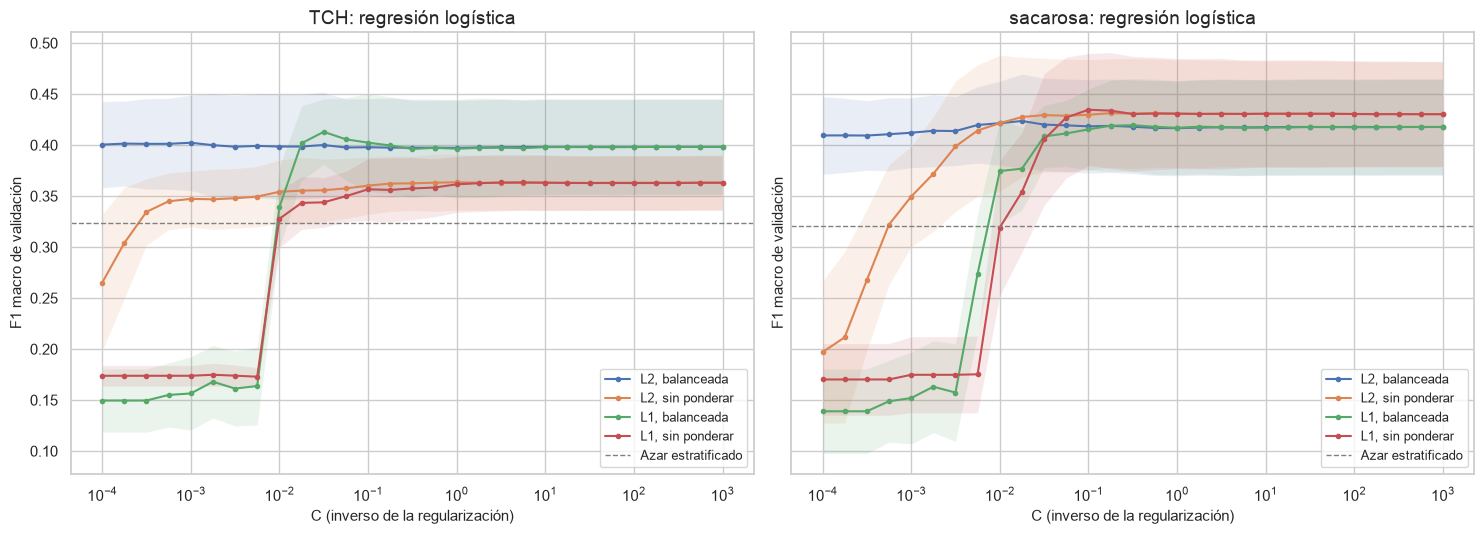

In [15]:
# 5.2 Regresión logística multinomial: búsqueda de C, tipo de penalización y ponderación de clases
GRILLA_LOGISTICA = {
    "modelo__C": [float(valor) for valor in np.logspace(-4, 3, 29)],  # cuatro valores por década
    "modelo__l1_ratio": [0.0, 1.0],                                    # 0 = L2, 1 = L1
    "modelo__class_weight": [None, "balanced"],
}

for target in COLUMNA_CODIGO:
    pipeline_logistica = Pipeline([
        ("preprocesamiento", crear_preprocesador()),
        ("modelo", LogisticRegression(solver="saga", max_iter=5000, random_state=RANDOM_STATE)),
    ])
    busqueda = buscar_hiperparametros(MODELO_REFERENCIA, "log", pipeline_logistica, GRILLA_LOGISTICA, target)
    print(f"  Configuración elegida: {busqueda.best_params_} | en el extremo de la grilla: "
          f"{parametros_en_extremo(busqueda, GRILLA_LOGISTICA) or 'ninguno'}")

display(resumen_cv(["Azar estratificado", MODELO_REFERENCIA]).round(3))

# F1 macro de validación frente a C, por tipo de penalización y ponderación (banda: ± 1 desviación entre pliegues)
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for eje, target in zip(ejes, COLUMNA_CODIGO):
    resultados = pd.DataFrame(busquedas[(MODELO_REFERENCIA, target)].cv_results_)
    for (l1_ratio, ponderacion), grupo in resultados.groupby(["param_modelo__l1_ratio", "param_modelo__class_weight"],
                                                            dropna=False):
        grupo = grupo.sort_values("param_modelo__C")
        valores_c = grupo["param_modelo__C"].astype(float)
        etiqueta = f"{'L1' if l1_ratio == 1 else 'L2'}, {'balanceada' if ponderacion == 'balanced' else 'sin ponderar'}"
        eje.plot(valores_c, grupo["mean_test_f1_macro"], marker="o", markersize=3, label=etiqueta)
        eje.fill_between(valores_c, grupo["mean_test_f1_macro"] - grupo["std_test_f1_macro"],
                         grupo["mean_test_f1_macro"] + grupo["std_test_f1_macro"], alpha=0.12)
    piso = registro_cv[("Azar estratificado", target)]["f1_macro"].mean()
    eje.axhline(piso, color="gray", linestyle="--", linewidth=1, label="Azar estratificado")
    eje.set(xscale="log", xlabel="C (inverso de la regularización)", ylabel="F1 macro de validación",
            title=f"{target}: regresión logística")
    eje.legend(fontsize=9)
plt.tight_layout()
plt.show()

#### Conclusión de la búsqueda

| Target | `C` | Penalización | Ponderación | F1 macro | Kappa | Kappa lineal | Recall bajo | Precision bajo | Errores extremos | AUC bajo | F1 de ajuste |
|---|---|---|---|---|---|---|---|---|---|---|---|
| `TCH` | 0.032 | L1 | Balanceada | 0.413 ± 0.033 | 0.150 | 0.186 | 0.455 | 0.320 | 0.166 | 0.617 | 0.434 |
| Sacarosa | 0.1 | L1 | Sin ponderar | 0.435 ± 0.057 | 0.179 | 0.235 | 0.214 | 0.423 | 0.073 | 0.700 | 0.489 |

**Configuración elegida.** En los dos targets gana la penalización L1, con un `C` en el interior de la grilla (0.032 en `TCH` y 0.1 en sacarosa), así que la grilla cubre el óptimo.

**Forma de las curvas.**

- Con L1 y `C` menor que unos 0.006, la penalización anula todos los coeficientes, y el F1 macro cae a 0.14–0.17. Es el nivel del clasificador de la clase más frecuente: el modelo asigna la misma clase a todas las cosechas.
- Con L2 balanceada, el F1 macro se mantiene cerca de 0.40 incluso con la penalización más fuerte. L2 encoge los coeficientes sin anularlos, y la ponderación balanceada deja las tres clases con el mismo peso, así que la clase asignada depende del signo de coeficientes muy pequeños, que sigue siendo informativo.
- A partir de `C` ≈ 0.1, todas las curvas son planas hasta `C` = 1000. El desempeño no depende de un valor preciso de `C`. El máximo de L1 balanceada en `TCH` (0.413) supera en 0.015 a su meseta, una diferencia mucho menor que la desviación entre pliegues (0.033).
- **La ponderación de clases importa en `TCH` y no en sacarosa.** En `TCH`, la ponderación balanceada da un F1 macro cerca de 0.04 mayor en toda la zona plana (0.40 frente a 0.36). En sacarosa, las curvas con y sin ponderar quedan dentro de la misma banda.

**Frente a los clasificadores sin predictores.** La logística supera el piso en todas las métricas. El F1 macro sube de 0.32 a 0.41 y 0.44, el kappa de 0 a 0.15 y 0.18, y la AUC de la clase baja de 0.50 a 0.62 y 0.70. Los predictores disponibles al programar el corte sí distinguen las clases, aunque con un acuerdo leve: la señal es débil, como anticipaba el EDA.

- **Errores extremos.** En sacarosa, la logística los reduce de 0.20 (azar) a 0.07: casi nunca confunde una cosecha baja con una alta. En `TCH` la reducción es pequeña (de 0.19 a 0.17), así que el modelo capta poco el orden de las clases de tonelaje.
- **La clase baja se detecta de forma distinta en cada target.** En `TCH`, con ponderación balanceada, el modelo detecta el 45.5 % de las cosechas bajas, con una precision de 0.32. En sacarosa, sin ponderar, detecta solo el 21.4 %, por debajo del azar (26.2 %), pero cuando señala una cosecha como baja acierta en el 42.3 % de los casos. Además, la ordena mejor según su riesgo (AUC de 0.70 frente a 0.62). El modelo de sacarosa identifica qué cosechas tienen más probabilidad de ser bajas, pero esa probabilidad pocas veces supera a la de las otras dos clases.
- **Sobreajuste.** El F1 de ajuste supera al de validación en 0.021 en `TCH` y en 0.054 en sacarosa, diferencias del orden de la desviación entre pliegues. El modelo no memoriza el entrenamiento.
- **Variación entre pliegues.** La desviación del F1 macro en sacarosa (0.057) es casi el doble que en `TCH` (0.033), coherente con la variación de la composición de clases de sacarosa entre pliegues que se vio en 3.4.

#### Coeficientes y selección de variables

En la logística multinomial cada clase tiene su propio vector de coeficientes, y solo las diferencias entre clases tienen interpretación. La comparación más directa es entre la clase baja y la alta:

$$\log\frac{P(\text{bajo} \mid x)}{P(\text{alto} \mid x)} = (\beta_{0,\text{bajo}} - \beta_{0,\text{alto}}) + \sum_j (\beta_{\text{bajo},j} - \beta_{\text{alto},j})\, x_j.$$

Como los predictores están estandarizados, el contraste $\beta_{\text{bajo},j} - \beta_{\text{alto},j}$ es el cambio en ese logaritmo cuando el predictor $j$ aumenta una desviación estándar, con los demás fijos. Si es positivo, el predictor empuja la cosecha hacia la clase baja; si es negativo, hacia la alta. Su exponencial es la razón de odds: el factor por el que se multiplica el cociente entre la probabilidad de la clase baja y la de la alta.

Para cada target se analiza el modelo elegido, reentrenado con todo el entrenamiento:

- **Contraste y razón de odds** de cada columna, con la desviación estándar del predictor en unidades originales, para traducir el contraste a un cambio concreto.
- **Columnas eliminadas por L1:** las que tienen coeficiente 0 en las tres clases.
- **Estabilidad:** la misma configuración se ajusta en los 15 pliegues, y se cuenta en cuántos el contraste es distinto de 0 y en cuántos conserva el signo del modelo final. Un predictor que cambia de signo entre pliegues no tiene un efecto interpretable.
- **Mes de cosecha:** sus cuatro armónicos representan juntos la época de cosecha, así que no se leen por separado. Se combinan en la contribución de cada mes al contraste entre la clase baja y la alta.


TCH: 5 de 11 columnas eliminadas por L1


,β_bajo − β_alto,Razón de odds,Eliminada por L1,Pliegues con contraste ≠ 0,Pliegues con el signo del modelo final,Desviación estándar (unidades originales)
cortes,0.398,1.489,False,15,15,1.633
grupo_tenencia_3,-0.268,0.765,False,15,15,NaN
edad,-0.122,0.885,False,15,15,1.150
mes_cos_12,0.084,1.088,False,12,12,NaN
dosismad,-0.062,0.940,False,10,10,0.252
mes_cos_6,0.011,1.011,False,7,7,NaN
lluvias,0.000,1.000,True,9,6,121.803
semsmad,0.000,1.000,True,0,15,3.526
mes_sin_12,0.000,1.000,True,0,15,NaN
mes_sin_6,0.000,1.000,True,1,14,NaN



sacarosa: 0 de 11 columnas eliminadas por L1


,β_bajo − β_alto,Razón de odds,Eliminada por L1,Pliegues con contraste ≠ 0,Pliegues con el signo del modelo final,Desviación estándar (unidades originales)
mes_cos_12,-0.676,0.509,False,15,15,NaN
lluvias,0.600,1.821,False,15,15,121.701
mes_cos_6,0.595,1.814,False,15,15,NaN
semsmad,-0.278,0.757,False,15,15,3.530
mes_sin_12,0.193,1.213,False,13,13,NaN
mes_sin_6,0.176,1.192,False,15,15,NaN
grupo_tenencia_3,0.120,1.128,False,14,14,NaN
grupo_tenencia_2,-0.109,0.897,False,15,15,NaN
edad,0.015,1.015,False,10,10,1.151
cortes,0.000,1.000,False,5,10,1.631


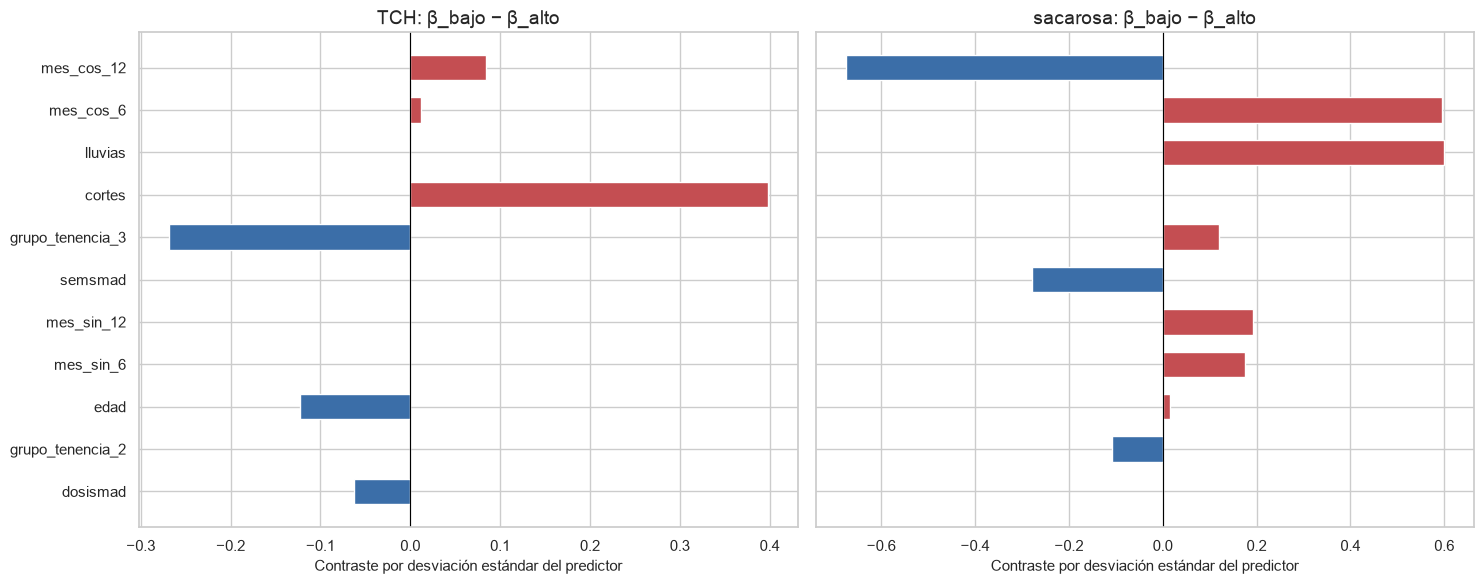

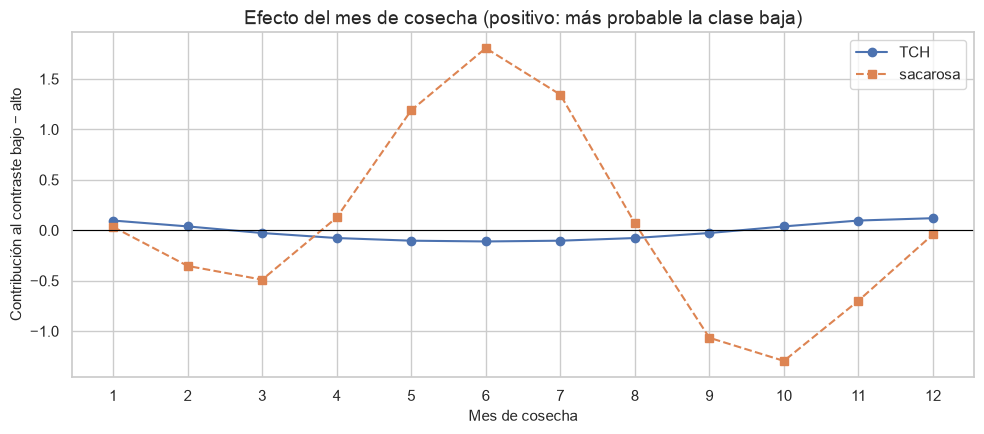

In [16]:
# 5.2 Coeficientes de la logística elegida: contraste bajo − alto, selección por L1 y estabilidad en los 15 pliegues
from sklearn.base import clone

CLASE_ALTA = CLASES.index("alto")  # 2
COLUMNAS_MES = columnas_armonicos
COLUMNAS_INDICADORAS = ["grupo_tenencia_2", "grupo_tenencia_3"]


def coeficientes_por_clase(pipeline):
    """Coeficientes del modelo final por clase (filas) y columna de la matriz de diseño (columnas)."""
    modelo = pipeline.named_steps["modelo"]
    return pd.DataFrame(modelo.coef_, index=modelo.classes_, columns=COLUMNAS_DISENO)


tablas_coeficientes, contrastes_finales, escaladores_finales = {}, {}, {}
for target in COLUMNA_CODIGO:
    modelo_final = busquedas[(MODELO_REFERENCIA, target)].best_estimator_
    coeficientes = coeficientes_por_clase(modelo_final)
    contraste = coeficientes.loc[CLASE_BAJA] - coeficientes.loc[CLASE_ALTA]

    # Estabilidad: la configuración elegida, ajustada en la parte de ajuste de cada uno de los 15 pliegues
    datos = datos_por_target[target]
    contrastes_pliegues = []
    for ajuste, _ in datos.pliegues:
        modelo_pliegue = clone(modelo_final).fit(datos.X_train.iloc[ajuste], datos.y_train.iloc[ajuste])
        coeficientes_pliegue = coeficientes_por_clase(modelo_pliegue)
        contrastes_pliegues.append(coeficientes_pliegue.loc[CLASE_BAJA] - coeficientes_pliegue.loc[CLASE_ALTA])
    contrastes_pliegues = pd.DataFrame(contrastes_pliegues)

    # Desviación estándar de cada columna en unidades originales (la del escalado ajustado con el entrenamiento)
    escalador = modelo_final.named_steps["preprocesamiento"].named_steps["escalado"]
    desviacion_original = pd.Series(escalador.scale_, index=COLUMNAS_DISENO)
    desviacion_original[COLUMNAS_MES + COLUMNAS_INDICADORAS] = np.nan  # sin lectura natural en unidades

    tabla = pd.DataFrame({
        "β_bajo − β_alto": contraste,
        "Razón de odds": np.exp(contraste),
        "Eliminada por L1": (coeficientes == 0).all(axis=0),
        "Pliegues con contraste ≠ 0": (contrastes_pliegues != 0).sum(),
        "Pliegues con el signo del modelo final": (np.sign(contrastes_pliegues) == np.sign(contraste)).sum(),
        "Desviación estándar (unidades originales)": desviacion_original,
    })
    tablas_coeficientes[target] = tabla.reindex(contraste.abs().sort_values(ascending=False).index)
    contrastes_finales[target], escaladores_finales[target] = contraste, escalador
    print(f"\n{target}: {int(tabla['Eliminada por L1'].sum())} de {len(tabla)} columnas eliminadas por L1")
    display(tablas_coeficientes[target].round(3))

# Contraste de cada columna en los dos targets, en el mismo orden (de mayor a menor contraste absoluto promedio)
COLOR_BAJO, COLOR_ALTO = "#C44E52", "#3B6EA8"  # hacia la clase baja / hacia la clase alta
orden_columnas = (pd.DataFrame(contrastes_finales).abs().mean(axis=1).sort_values().index)
fig, ejes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for eje, target in zip(ejes, COLUMNA_CODIGO):
    valores = contrastes_finales[target].loc[orden_columnas]
    eje.barh(orden_columnas, valores, color=np.where(valores > 0, COLOR_BAJO, COLOR_ALTO), height=0.6)
    eje.axvline(0, color="black", linewidth=0.8)
    eje.set(title=f"{target}: β_bajo − β_alto", xlabel="Contraste por desviación estándar del predictor")
plt.tight_layout()
plt.show()

# Contribución de cada mes al contraste: suma de los contrastes de los armónicos, evaluados en ese mes y escalados
meses = np.arange(1, 13)
armonicos_por_mes = pd.DataFrame(ArmonicosMes().fit_transform(meses.reshape(-1, 1)), index=meses,
                                 columns=COLUMNAS_MES)
fig, eje = plt.subplots(figsize=(10, 4.5))
for target, estilo in zip(COLUMNA_CODIGO, ["-o", "--s"]):
    escalador = escaladores_finales[target]
    posiciones = [COLUMNAS_DISENO.index(columna) for columna in COLUMNAS_MES]
    armonicos_escalados = (armonicos_por_mes - escalador.mean_[posiciones]) / escalador.scale_[posiciones]
    contribucion = armonicos_escalados @ contrastes_finales[target][COLUMNAS_MES]
    eje.plot(meses, contribucion, estilo, label=target)
eje.axhline(0, color="black", linewidth=0.8)
eje.set(xticks=meses, xlabel="Mes de cosecha", ylabel="Contribución al contraste bajo − alto",
        title="Efecto del mes de cosecha (positivo: más probable la clase baja)")
eje.legend()
plt.tight_layout()
plt.show()

In [17]:
# 5.2 Clases por código de tenencia en el entrenamiento, para leer los contrastes de las indicadoras
tabla_tenencia = {}
for target, datos in datos_por_target.items():
    codigo = datos.X_train["grupo_tenencia"]
    proporciones = pd.crosstab(codigo, datos.y_train, normalize="index") * 100
    tabla_tenencia[(target, "Cosechas")] = codigo.value_counts().sort_index()
    tabla_tenencia[(target, "% bajo")] = proporciones[CLASE_BAJA]
    tabla_tenencia[(target, "% alto")] = proporciones[CLASE_ALTA]
display(pd.DataFrame(tabla_tenencia).rename_axis("Código de tenencia").round(1))

TCH               sacarosa              
                   Cosechas % bajo % alto Cosechas % bajo % alto
Código de tenencia                                              
1                       220   31.4   30.0      220   19.5   42.3
2                       532   27.4   33.5      534   19.1   46.1
3                       981   18.0   43.1      983   23.3   39.5

#### Lectura de los coeficientes

**`TCH`.** L1 deja 6 de las 11 columnas. Solo 3 de ellas tienen un contraste distinto de 0 y con el mismo signo en los 15 pliegues:

- **Número de corte.** Es el predictor con más peso. Con cada 1.63 cortes más (una desviación estándar), las odds de la clase baja frente a la alta se multiplican por 1.49. Las socas avanzadas rinden menos, como mostró el EDA.
- **Edad del cultivo.** Con 1.15 meses más de edad, las odds de la clase baja frente a la alta se multiplican por 0.885. La caña que se deja crecer más tiempo acumula más biomasa.
- **Tenencia 3.** Su contraste negativo indica que las haciendas con código 3 tienden a la clase alta. La tabla anterior lo confirma: en el entrenamiento, el 18.0 % de sus cosechas es de clase baja y el 43.1 % de clase alta, frente a 27.4–31.4 % y 30.0–33.5 % en los códigos 1 y 2. Como las indicadoras también están estandarizadas, el contraste corresponde a una desviación estándar de la indicadora y no a la diferencia directa entre códigos, así que de esta columna solo se leen el signo y la estabilidad. L1 elimina la indicadora del código 2, cuya composición de clases se aparta poco de la del código 1.

El mes tiene un efecto pequeño en `TCH`: su contribución al contraste no pasa de ±0.12 en ningún mes, coherente con que el EDA no encontró estacionalidad en el tonelaje. `dosismad` y `mes_cos_6` conservan el signo en solo 10 y 7 pliegues, así que no se interpretan. L1 elimina `lluvias` en el modelo final, aunque la conserva en 9 de los 15 pliegues. En el EDA su relación con el `TCH` venía sobre todo de 2017, el año con más lluvia y más tonelaje, y `anio` no está entre los predictores.

**Sacarosa.** L1 no elimina ninguna columna, pero no todas se leen:

- **Época de cosecha.** Es el efecto más fuerte. La contribución del mes favorece la clase baja entre mayo y julio, con el máximo en junio (+1.8), y la clase alta en marzo y entre septiembre y noviembre, con el mínimo en octubre (−1.3). Es el mismo calendario de las medianas mensuales del EDA, que relacionó la sacarosa alta con las cosechas que siguen a las temporadas secas [2].
- **Lluvia.** Con 121.7 mm más, las odds de la clase baja frente a la alta se multiplican por 1.82, con el mes fijo. Hay un efecto de la lluvia medida además del que ya recoge la época del año: el agua al final del ciclo diluye la sacarosa.
- **Semanas desde el madurante.** Con 3.53 semanas más, las odds se multiplican por 0.757. La caña cosechada más tiempo después de la aplicación tiende a la clase alta, coherente con el EDA, donde la sacarosa sube hasta unas 12 semanas desde la aplicación.
- **Tenencia.** Los signos de las dos indicadoras son estables (14 y 15 pliegues) y coinciden con la tabla anterior. El código 3 tiene la mayor proporción de clase baja (23.3 %) y la menor de clase alta (39.5 %). El código 2 tiene la mayor de clase alta (46.1 %). Las diferencias son de pocos puntos, y su peso en el modelo es pequeño.

La edad, el número de corte y la dosis de madurante tienen un contraste nulo o casi nulo y sin signo estable. El EDA no relacionó el número de corte ni la dosis con la sacarosa. La edad sí se relacionaba con ella, pero en forma de U invertida, que un coeficiente lineal no puede representar: los efectos de signo contrario a cada lado del máximo se compensan.

Los contrastes describen asociaciones con los demás predictores fijos, no efectos causales. Las cosechas de una misma hacienda comparten manejo y suelo, y ninguna de las dos cosas está en los datos.

#### Conclusión de 5.2

La logística multinomial queda como modelo de referencia para la regla de selección. Sus configuraciones son L1 balanceada con `C` = 0.032 en `TCH` y L1 sin ponderar con `C` = 0.1 en sacarosa, con un F1 macro de validación de 0.413 y 0.435. Su desempeño no depende de un valor preciso de `C`, así que la referencia no es fruto de un ajuste fino.

Los coeficientes estables cuentan una historia distinta para cada target, la misma que el EDA:

- En `TCH`, el número de corte, la edad y la tenencia.
- En sacarosa, la época de cosecha, la lluvia y las semanas desde el madurante.

En los dos casos la señal es débil. El modelo solo puede representar efectos aditivos y monótonos, y eso deja fuera relaciones que el EDA sugiere, como la de la edad con la sacarosa. Los modelos de la sección 6 se evaluarán contra esta referencia.

### 5.3 K vecinos más cercanos

KNN es el segundo modelo de referencia. No supone fronteras lineales: clasifica cada cosecha según las cosechas de entrenamiento más parecidas en las 11 columnas de la matriz de diseño, con el mismo preprocesador estandarizado de la logística.

La búsqueda cubre tres hiperparámetros:

- **Número de vecinos `k`**, de 1 a 301. Va de dos en dos hasta 29, de seis en seis hasta 101 y con cinco valores más hasta 301, el 25 % de la parte de ajuste más pequeña. Con una señal débil, el mejor `k` puede ser grande, y la grilla tiene que poder mostrarlo.
- **Peso de los vecinos:** uniforme o inverso a la distancia.
- **Distancia:** Manhattan (`p` = 1) o euclidiana (`p` = 2).

Son 128 configuraciones, evaluadas en los mismos 15 pliegues y con el mismo criterio. KNN no admite ponderación de clases, así que en `TCH` compite sin el ajuste que más ayudó a la logística.

TCH | KNN: búsqueda cargada de resultados/clf_knn_tch.joblib (0.2 min)
  Configuración elegida: {'modelo__n_neighbors': 19, 'modelo__p': 2, 'modelo__weights': 'uniform'} | en el extremo de la grilla: ninguno
sacarosa | KNN: búsqueda cargada de resultados/clf_knn_sac.joblib (0.2 min)
  Configuración elegida: {'modelo__n_neighbors': 47, 'modelo__p': 2, 'modelo__weights': 'uniform'} | en el extremo de la grilla: ninguno


,,f1_macro mean,f1_macro std,kappa mean,kappa std,kappa_lineal mean,kappa_lineal std,recall_bajo mean,recall_bajo std,precision_bajo mean,precision_bajo std,errores_extremos mean,errores_extremos std,auc_bajo mean,auc_bajo std,f1_macro_ajuste mean,f1_macro_ajuste std
Target,Modelo,,,,,,,,,,,,,,,,
TCH,Azar estratificado,0.324,0.033,-0.009,0.043,-0.016,0.047,0.244,0.051,0.216,0.053,0.190,0.016,0.494,0.030,0.333,0.011
sacarosa,Azar estratificado,0.321,0.035,-0.003,0.045,-0.004,0.048,0.262,0.059,0.241,0.108,0.202,0.037,0.510,0.031,0.335,0.010
TCH,Regresión logística,0.413,0.033,0.150,0.048,0.186,0.060,0.455,0.055,0.320,0.057,0.166,0.025,0.617,0.063,0.434,0.012
sacarosa,Regresión logística,0.435,0.057,0.179,0.108,0.235,0.103,0.214,0.105,0.423,0.158,0.073,0.022,0.700,0.058,0.489,0.021
TCH,KNN,0.365,0.031,0.072,0.040,0.103,0.050,0.137,0.058,0.287,0.093,0.105,0.023,0.558,0.060,0.518,0.016
sacarosa,KNN,0.426,0.061,0.157,0.083,0.210,0.092,0.269,0.130,0.420,0.115,0.092,0.031,0.688,0.071,0.523,0.018


,diferencia media,pliegues en que gana,supera la regla
TCH,-0.047667,2,False
sacarosa,-0.008258,5,False


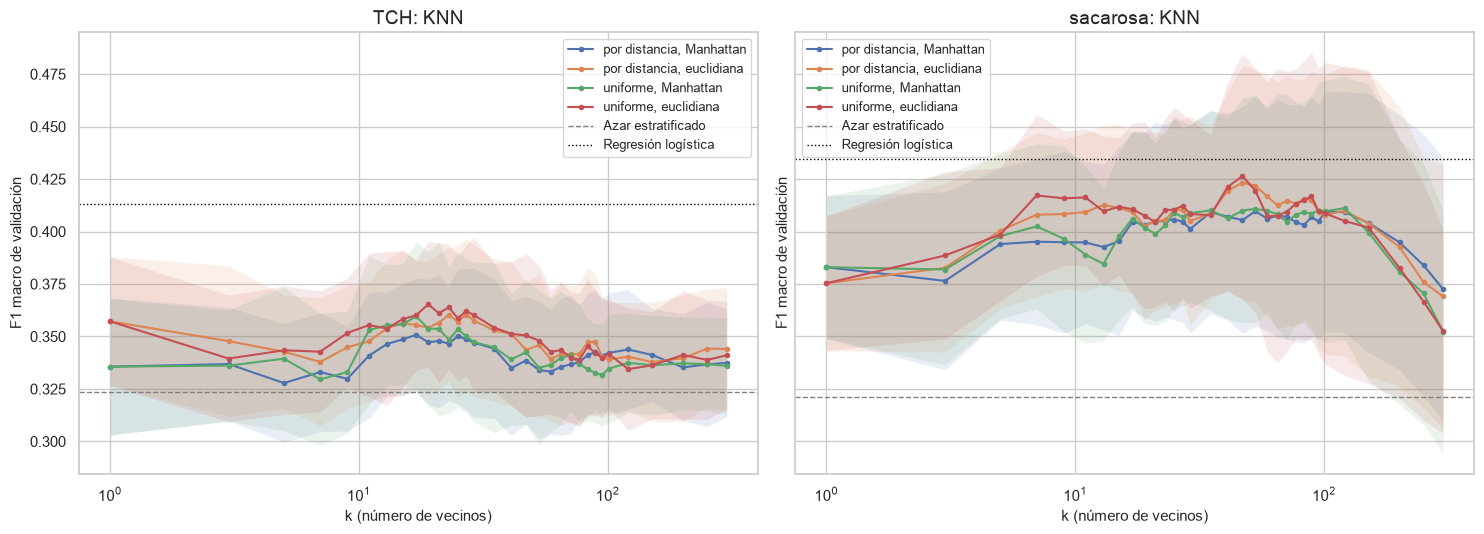

In [18]:
# 5.3 KNN: búsqueda de k, peso de los vecinos y distancia
MODELO_KNN = "KNN"
VALORES_K = list(range(1, 30, 2)) + list(range(35, 102, 6)) + [121, 151, 201, 251, 301]

GRILLA_KNN = {
    "modelo__n_neighbors": VALORES_K,
    "modelo__weights": ["uniform", "distance"],
    "modelo__p": [1, 2],  # 1 = Manhattan, 2 = euclidiana
}

for target in COLUMNA_CODIGO:
    pipeline_knn = Pipeline([
        ("preprocesamiento", crear_preprocesador()),
        ("modelo", KNeighborsClassifier()),
    ])
    busqueda = buscar_hiperparametros(MODELO_KNN, "knn", pipeline_knn, GRILLA_KNN, target)
    print(f"  Configuración elegida: {busqueda.best_params_} | en el extremo de la grilla: "
          f"{parametros_en_extremo(busqueda, GRILLA_KNN) or 'ninguno'}")

display(resumen_cv(["Azar estratificado", MODELO_REFERENCIA, MODELO_KNN]).round(3))

# Regla de selección: KNN frente a la logística en los 15 pliegues
display(pd.DataFrame({target: comparar_pliegues(MODELO_KNN, MODELO_REFERENCIA, target)
                      for target in COLUMNA_CODIGO}).T)

# F1 macro de validación frente a k, por peso y distancia (banda: ± 1 desviación entre pliegues)
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for eje, target in zip(ejes, COLUMNA_CODIGO):
    resultados = pd.DataFrame(busquedas[(MODELO_KNN, target)].cv_results_)
    for (peso, p), grupo in resultados.groupby(["param_modelo__weights", "param_modelo__p"]):
        grupo = grupo.sort_values("param_modelo__n_neighbors")
        valores_k = grupo["param_modelo__n_neighbors"].astype(int)
        etiqueta = f"{'uniforme' if peso == 'uniform' else 'por distancia'}, {'Manhattan' if p == 1 else 'euclidiana'}"
        eje.plot(valores_k, grupo["mean_test_f1_macro"], marker="o", markersize=3, label=etiqueta)
        eje.fill_between(valores_k, grupo["mean_test_f1_macro"] - grupo["std_test_f1_macro"],
                         grupo["mean_test_f1_macro"] + grupo["std_test_f1_macro"], alpha=0.12)
    eje.axhline(registro_cv[("Azar estratificado", target)]["f1_macro"].mean(), color="gray", linestyle="--",
                linewidth=1, label="Azar estratificado")
    eje.axhline(registro_cv[(MODELO_REFERENCIA, target)]["f1_macro"].mean(), color="black", linestyle=":",
                linewidth=1, label="Regresión logística")
    eje.set(xscale="log", xlabel="k (número de vecinos)", ylabel="F1 macro de validación",
            title=f"{target}: KNN")
    eje.legend(fontsize=9)
plt.tight_layout()
plt.show()

#### Conclusión de 5.3

| Target | `k` | Peso | Distancia | F1 macro | Kappa | Kappa lineal | Recall bajo | Precision bajo | Errores extremos | AUC bajo | F1 de ajuste |
|---|---|---|---|---|---|---|---|---|---|---|---|
| `TCH` | 19 | Uniforme | Euclidiana | 0.365 ± 0.031 | 0.072 | 0.103 | 0.137 | 0.287 | 0.105 | 0.558 | 0.518 |
| Sacarosa | 47 | Uniforme | Euclidiana | 0.426 ± 0.061 | 0.157 | 0.210 | 0.269 | 0.420 | 0.092 | 0.688 | 0.523 |

**La grilla cubre el óptimo.** En los dos targets el mejor `k` queda en el interior del rango. En `TCH`, el F1 macro sube hasta `k` ≈ 19 y luego baja hacia 0.34. En sacarosa, se mantiene entre 0.40 y 0.42 desde `k` ≈ 7 hasta `k` ≈ 120, y a partir de 150 cae hasta 0.35–0.37 con 301 vecinos. Las cuatro combinaciones de peso y distancia quedan dentro de la misma banda: ponderar por la distancia no mejora a KNN, y la diferencia entre Manhattan y euclidiana es menor que la variación entre pliegues.

**KNN no supera a la logística.** En `TCH` queda 0.048 por debajo en F1 macro y gana solo en 2 de los 15 pliegues. En sacarosa la diferencia media es pequeña (−0.008), pero gana solo en 5 de 15. Con la regla de 4.2, ninguno de los dos KNN reemplaza a la logística.

- **En `TCH`, la desventaja coincide con la falta de ponderación de clases.** El F1 macro de KNN (0.365) es el mismo de la logística sin ponderar en su zona plana (0.36). Sin ponderación, KNN casi no asigna la clase baja: detecta el 13.7 % de las cosechas bajas, menos que el azar (24.4 %). La tasa de errores extremos es menor que la de la logística (0.105 frente a 0.166) porque el modelo casi no predice la clase baja, no porque ordene mejor las clases: su kappa lineal es más bajo (0.103 frente a 0.186).
- **En sacarosa, KNN se acerca a la logística sin superarla.** Con todas sus métricas a menos de 0.03 de las de la logística, buscar vecinos parecidos no capta una estructura que el modelo lineal no tenga ya.
- **Sobreajuste.** El F1 de ajuste supera al de validación en 0.15 en `TCH` y en 0.10 en sacarosa, más que en la logística. Parte de la diferencia es mecánica: al medir en los datos de ajuste, cada cosecha es uno de sus propios vecinos.

### Conclusión de la sección 5

| Target | Modelo | F1 macro | Kappa | Recall bajo | AUC bajo |
|---|---|---|---|---|---|
| `TCH` | Azar estratificado | 0.324 | −0.009 | 0.244 | 0.494 |
| `TCH` | Regresión logística | **0.413** | **0.150** | **0.455** | **0.617** |
| `TCH` | KNN | 0.365 | 0.072 | 0.137 | 0.558 |
| Sacarosa | Azar estratificado | 0.321 | −0.003 | 0.262 | 0.510 |
| Sacarosa | Regresión logística | **0.435** | **0.179** | 0.214 | **0.700** |
| Sacarosa | KNN | 0.426 | 0.157 | **0.269** | 0.688 |

Los dos modelos de referencia superan el piso de los clasificadores sin predictores en las métricas globales: los predictores disponibles al programar el corte sí distinguen las clases. La logística es el mejor de los dos en ambos targets, y queda como referencia para la regla de selección.

El acuerdo con la clase real sigue siendo leve, con un kappa de 0.15 a 0.18. En `TCH`, la ventaja de la logística sobre KNN coincide con la ponderación de clases. En sacarosa, el modelo lineal y el local llegan a niveles parecidos. La sección 6 prueba si hay algo más que capturar: efectos no monótonos, interacciones entre variables y la información de la cosecha anterior de cada suerte.

## 6. Modelos avanzados

La logística solo representa efectos aditivos y monótonos. Con los predictores disponibles hay razones agronómicas para esperar algo más:

- **Efectos no monótonos.** El EDA encontró que la sacarosa tiene una relación en forma de U invertida con la edad, con el máximo hacia los 12.5 meses, y que crece con las semanas desde el madurante hasta unas 12 semanas y después se estabiliza. Un coeficiente lineal no representa ninguna de las dos formas.
- **Lluvia y época de cosecha.** La misma cantidad de lluvia no debería tener el mismo efecto en todos los meses: el agua al final del ciclo diluye la sacarosa, pero su efecto depende de cuándo cae.
- **Edad y semanas desde el madurante.** El madurante actúa sobre la caña madura, así que el tiempo desde su aplicación debería pesar distinto según la edad del cultivo.
- **Número de corte y edad.** Una soca avanzada puede necesitar más tiempo para alcanzar el mismo tonelaje.

Son hipótesis, no hallazgos. El IPSA no trae variables de suelo, y todas las cosechas son de la variedad CC01-1940. En el histórico de suertes, el efecto de la lluvia temprana sobre el `TCH` cambiaba de signo según la variedad, así que aquí no hay forma de capturar ese tipo de interacción. La señal es débil, así que un modelo más flexible también puede sobreajustar sin ganar nada.

La sección prueba cinco alternativas, con los mismos pliegues, métricas y regla de selección:

1. **Random Forest (6.1)**
2. **XGBoost (6.2)**
3. **SVM con kernel RBF (6.3)**
4. **Historial de la suerte (6.4):** el resultado de la cosecha anterior de cada suerte como predictor adicional.
5. **Regresión con umbrales (6.5):** predecir el valor continuo de cada target y asignar la clase con los umbrales del Ingenio.

### 6.1 Random Forest

**Búsqueda por etapas.** Random Forest y XGBoost tienen varios hiperparámetros, y una grilla con todas sus combinaciones sería inviable. La búsqueda se hace por etapas: en cada una, `GridSearchCV` prueba todas las combinaciones de un grupo de hiperparámetros que interactúan entre sí, con los mejores valores de las etapas anteriores fijos. Cada grilla incluye el valor vigente, así que el F1 macro de validación no puede empeorar de una etapa a la siguiente. La búsqueda supone que la interacción entre grupos es menor que dentro de cada grupo. Para verificarlo, la última etapa repite la primera con los valores finales de las demás.

| Etapa | Hiperparámetro | Qué controla | Valores |
|---|---|---|---|
| 1. Estructura y ponderación | `max_features` | Número de columnas que se considera en cada división, de 1 a las 11 de la matriz de diseño | 1, 2, 3, 4, 6, 8, 11 |
| | `min_samples_leaf` | Mínimo de cosechas por hoja. Con una señal débil, hojas grandes pueden generalizar mejor, así que el rango llega hasta 80 | 1, 2, 5, 10, 20, 40, 80 |
| | `class_weight` | Peso de cada clase. `balanced_subsample` recalcula los pesos en la muestra de cada árbol | Sin ponderar, `balanced`, `balanced_subsample` |
| 2. Criterio, muestreo y profundidad | `criterion` | Medida de impureza de las divisiones | Gini, entropía |
| | `max_samples` | Fracción del entrenamiento en la muestra de cada árbol | 0.5, 0.75, completa |
| | `max_depth` | Profundidad máxima de cada árbol | 4, 8, 12, sin límite |
| 3. Número de árboles | `n_estimators` | Cuántos árboles se promedian. Esta etapa comprueba desde cuántos deja de mejorar el F1 | 150, 300, 600, 1000 |
| 4. Revisión de la estructura | `max_features`, `min_samples_leaf`, `class_weight` | Segunda pasada de la etapa 1 con las demás etapas ya fijadas | Los de la etapa 1 |

En total son 322 configuraciones por target. Los valores iniciales son los de la librería, con 300 árboles. La ponderación está en la primera etapa porque fue lo que más cambió el desempeño de la logística en `TCH`, y su efecto depende del tamaño de las hojas.

**Hiperparámetros que no se buscan.** `min_samples_split` es redundante con `min_samples_leaf`. `max_leaf_nodes`, `min_impurity_decrease` y `ccp_alpha` son otras formas de limitar el tamaño de los árboles, que ya controlan `min_samples_leaf` y `max_depth`.

Los árboles no necesitan variables escaladas, así que el preprocesador se usa sin el escalado. La imputación y los armónicos del mes son los mismos de los demás modelos.

[3] scikit-learn developers, “StratifiedGroupKFold,” scikit-learn 1.9 documentation. [En línea]. Disponible: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html